# Analysis of Factors Affecting DO — PCA Approach (v2)

This notebook analyzes how the Principal Component (PC) scores from the PCA analysis (`12_PCA_analysis_continue.ipynb`) relate to the **time series** of various environmental parameters.

**Key differences from Notebook 32:**
- Uses **PCA scores (PC1 & PC2)** instead of decorrelation scale
- Uses **time series data** per station instead of climatological means
- Calculates **per-station Pearson correlations** between PC scores and each parameter's time series

**Parameters analyzed:**
1. Summer Sea Surface Temperature (SST)
2. Summer Sea Bottom Temperature (SBT)
3. Summer Sea Surface Salinity (SSS)
4. Summer Sea Bottom Salinity (SBS)
5. Summer Surface Density (σ₀)
6. Summer Bottom Density (σ₀)
7. Summer Wind Speed
8. Winter Air Temperature
9. Spring Chlorophyll-a

In [1]:
import pandas as pd
import numpy as np
import gsw
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from scipy import stats
from scipy.stats import pearsonr

import sys
project_root = Path("../").resolve()
if str(project_root) not in sys.path:
    sys.path.append(str(project_root))

from scripts.paths import ProjectPaths

import warnings
warnings.filterwarnings('ignore')

# Configure plotting
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)

## 1. Load Data

In [2]:
# Load main dataset
merged_df = pd.read_feather(ProjectPaths.MERGED_DATA_FILE)
merged_df['zettaicode'] = merged_df['zettaicode'].astype(str).str.zfill(8)

# Load PCA Scores (Summer Bottom subset — same as notebook 12)
season = 'Summer'
layer = 'bottom'
subset_dir = ProjectPaths.get_subset_dir(season, layer)
pca_scores_path = subset_dir / 'pca_scores.csv'
pca_scores = pd.read_csv(pca_scores_path, index_col=0)
pca_scores.index = pca_scores.index.astype(int)

# Extract unique stations with lat/lon
stations = merged_df[['zettaicode', 'latitude', 'longitude']].drop_duplicates('zettaicode').set_index('zettaicode')

print(f"Loaded merged data: {merged_df.shape}")
print(f"Loaded PCA scores: {pca_scores.shape}")
print(f"PCA year range: {pca_scores.index.min()} – {pca_scores.index.max()}")
print(f"Total unique stations: {len(stations)}")

Loaded merged data: (42326, 65)
Loaded PCA scores: (41, 41)
PCA year range: 1982 – 2023
Total unique stations: 127


## 2. Build Time Series Matrices (Year × Station)

For each parameter, we build a matrix where rows = years and columns = stations.
This replaces the climatological mean approach in Notebook 32.

In [3]:
def get_time_series_matrix(df, param, season_filter, saisuipoin=None):
    """
    Build a Year × Station matrix for a given parameter.
    
    Parameters
    ----------
    df : DataFrame — merged data
    param : str — column name of the parameter
    season_filter : str — season to filter by
    saisuipoin : int or None — 1=surface, 2=bottom, None=all
    
    Returns
    -------
    DataFrame with years as rows, stations as columns
    """
    mask = df['season'] == season_filter
    if saisuipoin is not None:
        mask &= df['saisuipoin'] == saisuipoin
    
    subset = df.loc[mask, ['surveyyear', 'zettaicode', param]].copy()
    subset[param] = pd.to_numeric(subset[param], errors='coerce')
    
    # Group by year + station → mean, then pivot
    matrix = subset.groupby(['surveyyear', 'zettaicode'])[param].mean().unstack()
    matrix.index = matrix.index.astype(int)
    matrix.index.name = 'year'
    
    return matrix


# 1. Summer SST (surface temp)
sst_matrix = get_time_series_matrix(merged_df, 'wtemp', 'Summer', saisuipoin=1)

# 2. Summer SBT (bottom temp)
sbt_matrix = get_time_series_matrix(merged_df, 'wtemp', 'Summer', saisuipoin=2)

# 3. Summer SSS (surface salinity)
sss_matrix = get_time_series_matrix(merged_df, 'salt', 'Summer', saisuipoin=1)

# 4. Summer SBS (bottom salinity)
sbs_matrix = get_time_series_matrix(merged_df, 'salt', 'Summer', saisuipoin=2)

# 5. Summer Wind Speed (no saisuipoin filter)
wind_matrix = get_time_series_matrix(merged_df, 'fusoku', 'Summer')

# 6. Winter Air Temperature (no saisuipoin filter)
air_t_matrix = get_time_series_matrix(merged_df, 'temp', 'Winter')

# 7. Spring Chlorophyll-a (no saisuipoin filter)
chla_matrix = get_time_series_matrix(merged_df, 'chlorophyl', 'Spring')

print("Time series matrices built:")
for name, mat in [('SST', sst_matrix), ('SBT', sbt_matrix), 
                   ('SSS', sss_matrix), ('SBS', sbs_matrix),
                   ('Wind', wind_matrix), ('Air Temp', air_t_matrix), 
                   ('Chl-a', chla_matrix)]:
    print(f"  {name:>10s}: {mat.shape[0]} years × {mat.shape[1]} stations")

Time series matrices built:
         SST: 43 years × 127 stations
         SBT: 43 years × 127 stations
         SSS: 43 years × 127 stations
         SBS: 43 years × 127 stations
        Wind: 43 years × 127 stations
    Air Temp: 43 years × 127 stations
       Chl-a: 43 years × 124 stations


## 3. Density Time Series Calculation using `gsw-python`

Calculate Sigma-0 density from Absolute Salinity and Conservative Temperature for each year and station.

### 3.1 Stratification Index Calculation
To assess the vertical stability of the water column, we calculate a **Stratification Index** defined as the vertical density gradient. This index represents the rate of change of water density per unit of depth:

$$Stratification\ Index = \frac{\rho_{bottom} - \rho_{surface}}{Depth_{bottom} - Depth_{surface}}$$

Where:
*   $\rho$ is the $\sigma_0$ density ($kg/m^3$) calculated using `gsw-python`.
*   $Depth$ is the recorded sampling depth ($m$) for surface (`saisuipoin=1`) and bottom (`saisuipoin=2`).

A higher stratification index indicates a stronger density barrier between layers, which often inhibits vertical mixing and can influence bottom-water DO levels.

In [4]:
# Compute density time series for surface and bottom
# We need lat/lon per station for gsw calculations
station_coords = stations[['latitude', 'longitude']]

def compute_density_matrix(temp_matrix, salt_matrix, station_coords):
    """
    Compute σ₀ density for each year × station from temp and salinity matrices.
    Uses gsw to convert from practical salinity and in-situ temperature.
    """
    density_matrix = pd.DataFrame(index=temp_matrix.index, columns=temp_matrix.columns, dtype=float)
    
    # Get common stations
    common_stations = temp_matrix.columns.intersection(salt_matrix.columns).intersection(station_coords.index)
    
    for stn in common_stations:
        lat = station_coords.loc[stn, 'latitude']
        lon = station_coords.loc[stn, 'longitude']
        
        t = temp_matrix[stn]
        s = salt_matrix[stn]
        
        # Both must be valid
        valid = t.notna() & s.notna()
        if valid.sum() == 0:
            continue
        
        SA = gsw.SA_from_SP(s[valid], 0, lon, lat)
        CT = gsw.CT_from_t(SA, t[valid], 0)
        sigma0 = gsw.sigma0(SA, CT)
        
        density_matrix.loc[valid, stn] = sigma0.values
    
    density_matrix.index.name = 'year'
    return density_matrix.astype(float)


surface_density_matrix = compute_density_matrix(sst_matrix, sss_matrix, station_coords)
bottom_density_matrix = compute_density_matrix(sbt_matrix, sbs_matrix, station_coords)


# 1. Build time series matrices for sampling depths
surface_depth_matrix = get_time_series_matrix(merged_df, 'saisuidept', 'Summer', saisuipoin=1)
bottom_depth_matrix = get_time_series_matrix(merged_df, 'saisuidept', 'Summer', saisuipoin=2)

# 2. Calculate the distance/depth difference between bottom and surface
depth_diff_matrix = bottom_depth_matrix - surface_depth_matrix

# Avoid division by zero if depths are identical or invalid
depth_diff_matrix = depth_diff_matrix.replace(0, np.nan)

# 3. Calculate Stratification Index (Δ Density / Δ Depth)
stratification_matrix = (bottom_density_matrix - surface_density_matrix) / depth_diff_matrix

print(f"Surface density matrix: {surface_density_matrix.shape}")
print(f"Bottom density matrix:  {bottom_density_matrix.shape}")

Surface density matrix: (43, 127)
Bottom density matrix:  (43, 127)


## 4. Calculate Per-Station Correlations: PC Scores vs. Parameter Time Series

For each station, we calculate the **Pearson correlation** between the PC score time series and each parameter's time series at that station.

This produces two DataFrames:
- `corr_df_pc1`: correlation of **PC1** with each parameter for every station
- `corr_df_pc2`: correlation of **PC2** with each parameter for every station

In [5]:
def calculate_station_correlations(pc_series, env_matrices, param_names, min_years=5):
    """
    Calculate per-station Pearson correlation between a PC score time series
    and each environmental parameter's time series.
    
    Parameters
    ----------
    pc_series : Series — PC scores indexed by year
    env_matrices : list of DataFrames — each is Year × Station
    param_names : list of str — column names for output
    min_years : int — minimum overlapping years required
    
    Returns
    -------
    corr_df : DataFrame — stations × parameters (correlation values)
    pval_df : DataFrame — stations × parameters (p-values)
    n_df    : DataFrame — stations × parameters (sample sizes)
    """
    pc_series = pc_series.copy()
    pc_series.index = pc_series.index.astype(int)
    
    # Collect all stations across all matrices
    all_stations = set()
    for mat in env_matrices:
        all_stations.update(mat.columns)
    all_stations = sorted(all_stations)
    
    corr_records = []
    
    for stn in all_stations:
        row_corr = {'zettaicode': stn}
        row_pval = {'zettaicode': stn}
        row_n = {'zettaicode': stn}
        
        for mat, pname in zip(env_matrices, param_names):
            if stn not in mat.columns:
                row_corr[pname] = np.nan
                row_pval[pname + '_pval'] = np.nan
                row_n[pname + '_n'] = 0
                continue
            
            env_series = mat[stn].copy()
            env_series.index = env_series.index.astype(int)
            
            # Intersect years
            common_years = pc_series.index.intersection(env_series.index)
            s_pc = pc_series.loc[common_years]
            s_env = env_series.loc[common_years]
            
            # Drop NaN
            valid = s_pc.notna() & s_env.notna()
            n = valid.sum()
            
            if n >= min_years:
                r, p = pearsonr(s_pc[valid], s_env[valid])
                row_corr[pname] = r
                row_pval[pname + '_pval'] = p
                row_n[pname + '_n'] = n
            else:
                row_corr[pname] = np.nan
                row_pval[pname + '_pval'] = np.nan
                row_n[pname + '_n'] = n
        
        corr_records.append({**row_corr, **{k: v for k, v in row_pval.items() if k != 'zettaicode'}, 
                              **{k: v for k, v in row_n.items() if k != 'zettaicode'}})
    
    result = pd.DataFrame(corr_records).set_index('zettaicode')
    
    # Split into correlation values, p-values, and sample sizes
    corr_cols = param_names
    pval_cols = [p + '_pval' for p in param_names]
    n_cols = [p + '_n' for p in param_names]
    
    corr_df = result[corr_cols]
    pval_df = result[[c for c in pval_cols if c in result.columns]]
    n_df = result[[c for c in n_cols if c in result.columns]]
    
    return corr_df, pval_df, n_df


# Define all parameter matrices and their names
env_matrices = [
    sst_matrix, sbt_matrix, sss_matrix, sbs_matrix,
    surface_density_matrix, bottom_density_matrix, stratification_matrix,
    wind_matrix, air_t_matrix, chla_matrix
]
param_names = [
    'Summer_SST', 'Summer_SBT', 'Summer_SSS', 'Summer_SBS',
    'Summer_Surface_Density', 'Summer_Bottom_Density', 'Summer_Stratification',
    'Summer_Wind_Speed', 'Winter_Air_Temp', 'Spring_Chla'
]

# === PC1 Correlations ===
corr_df_pc1, pval_df_pc1, n_df_pc1 = calculate_station_correlations(
    pca_scores['PC1'], env_matrices, param_names
)

# === PC2 Correlations ===
corr_df_pc2, pval_df_pc2, n_df_pc2 = calculate_station_correlations(
    pca_scores['PC2'], env_matrices, param_names
)

print(f"corr_df_pc1: {corr_df_pc1.shape} (stations × parameters)")
print(f"corr_df_pc2: {corr_df_pc2.shape} (stations × parameters)")

corr_df_pc1: (127, 10) (stations × parameters)
corr_df_pc2: (127, 10) (stations × parameters)


# Display the PC1 correlation DataFrame
print("=" * 80)
print("PC1 Correlations: Per-station Pearson r between PC1 scores and parameter time series")
print("=" * 80)
display(corr_df_pc1)

In [6]:
# Display the PC2 correlation DataFrame
print("=" * 80)
print("PC2 Correlations: Per-station Pearson r between PC2 scores and parameter time series")
print("=" * 80)
display(corr_df_pc2)

PC2 Correlations: Per-station Pearson r between PC2 scores and parameter time series


,Summer_SST,Summer_SBT,Summer_SSS,Summer_SBS,Summer_Surface_Density,Summer_Bottom_Density,Summer_Stratification,Summer_Wind_Speed,Winter_Air_Temp,Spring_Chla
zettaicode,,,,,,,,,,
00000272,0.199386,0.102978,-0.040754,-0.196323,-0.064093,-0.241654,0.136614,-0.177827,-0.069976,0.147678
00000275,0.180005,-0.026910,0.104065,0.051840,0.066589,0.062021,0.004457,0.070113,0.075882,-0.147037
00002725,0.229918,0.073809,0.072402,0.106184,0.032295,0.052252,0.021773,0.108194,0.227675,-0.151201
00002737,0.085425,0.007849,0.123880,-0.202186,0.081070,-0.194595,-0.131939,0.266866,0.108176,0.015664
00002744,0.155729,0.009691,0.020092,-0.072899,-0.033347,-0.078040,0.010667,0.023996,0.128673,0.084738
...,...,...,...,...,...,...,...,...,...,...
00044679,-0.061811,-0.067783,-0.132853,-0.217923,0.003463,-0.062383,-0.015539,-0.077153,-0.008670,-0.050124
00044680,0.162363,0.032228,-0.114187,-0.189632,-0.203853,-0.121486,0.151049,-0.125759,0.020807,0.100898
00044690,-0.013542,-0.080459,-0.233032,-0.287722,-0.150822,-0.101036,0.125835,-0.240835,0.026367,0.115057


## 5. Pearson Correlation Summary

Summary statistics of the per-station correlations for each parameter.
This shows which parameters are most consistently correlated with PC1 and PC2 across all stations.

In [7]:
def summarize_correlations(corr_df, pval_df, pc_name):
    """
    Produce a summary table for per-station correlations.
    Shows mean, median, std, % significant stations, etc.
    """
    records = []
    for col in corr_df.columns:
        r_vals = corr_df[col].dropna()
        pval_col = col + '_pval'
        
        if pval_col in pval_df.columns:
            p_vals = pval_df[pval_col].dropna()
            n_sig = (p_vals < 0.05).sum()
            n_total = len(p_vals)
        else:
            n_sig = 0
            n_total = len(r_vals)
        
        records.append({
            'Parameter': col,
            'Mean_r': r_vals.mean(),
            'Median_r': r_vals.median(),
            'Std_r': r_vals.std(),
            'Min_r': r_vals.min(),
            'Max_r': r_vals.max(),
            'N_stations': len(r_vals),
            'N_significant (p<0.05)': n_sig,
            '% Significant': f"{100 * n_sig / n_total:.1f}%" if n_total > 0 else "N/A"
        })
    
    summary = pd.DataFrame(records).set_index('Parameter')
    summary = summary.sort_values('Mean_r', key=abs, ascending=False)
    
    print(f"\nPearson Correlation Summary: {pc_name} vs. Each Parameter (across all stations)")
    print("=" * 90)
    display(summary)
    
    return summary


summary_pc1 = summarize_correlations(corr_df_pc1, pval_df_pc1, 'PC1')
summary_pc2 = summarize_correlations(corr_df_pc2, pval_df_pc2, 'PC2')


Pearson Correlation Summary: PC1 vs. Each Parameter (across all stations)


,Mean_r,Median_r,Std_r,Min_r,Max_r,N_stations,N_significant (p<0.05),% Significant
Parameter,,,,,,,,
Spring_Chla,-0.270634,-0.291687,0.175074,-0.687332,0.190411,124,53,42.7%
Summer_Wind_Speed,-0.091021,-0.095994,0.202088,-0.603145,0.489190,108,7,6.5%
Summer_SBT,0.084342,0.104540,0.174412,-0.416226,0.461392,127,13,10.2%
Summer_Bottom_Density,-0.081333,-0.079004,0.199962,-0.487349,0.329913,127,21,16.5%
Summer_SST,0.077288,0.083952,0.148094,-0.363003,0.419173,127,7,5.5%
Winter_Air_Temp,0.073118,0.074125,0.203233,-0.317596,0.509006,127,18,14.2%
Summer_SBS,-0.050308,-0.074580,0.229104,-0.563131,0.427383,127,24,18.9%
Summer_Surface_Density,-0.048352,-0.049005,0.171272,-0.422674,0.364683,127,13,10.2%
Summer_Stratification,-0.031584,-0.032940,0.192344,-0.434333,0.509433,127,15,11.8%



Pearson Correlation Summary: PC2 vs. Each Parameter (across all stations)


,Mean_r,Median_r,Std_r,Min_r,Max_r,N_stations,N_significant (p<0.05),% Significant
Parameter,,,,,,,,
Summer_Surface_Density,-0.170529,-0.177349,0.148307,-0.644102,0.195434,127,16,12.6%
Summer_SBS,-0.168888,-0.207788,0.165506,-0.604317,0.315603,127,20,15.7%
Summer_SST,0.148255,0.153652,0.146602,-0.338915,0.445880,127,16,12.6%
Summer_SSS,-0.133554,-0.128320,0.145263,-0.644063,0.278158,127,14,11.0%
Summer_Stratification,0.129935,0.127661,0.145617,-0.206116,0.618606,127,12,9.4%
Summer_Bottom_Density,-0.125770,-0.108659,0.158637,-0.738889,0.321521,127,15,11.8%
Spring_Chla,0.068622,0.074105,0.191825,-0.393361,0.476195,124,17,13.7%
Summer_Wind_Speed,-0.067038,-0.064224,0.165891,-0.519174,0.378664,108,7,6.5%
Winter_Air_Temp,0.055988,0.031903,0.131276,-0.277912,0.409112,127,4,3.1%


## 6. Random Forest Regressor

Predict PC scores from the environmental parameter time series.
For each year, we aggregate each parameter across stations (mean) to create year-level features, then predict the PC1 / PC2 scores.

This mirrors the Random Forest approach in Notebook 32 (which predicted decorrelation scale from climatological means).

In [8]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import cross_val_score, LeaveOneOut
from sklearn.preprocessing import StandardScaler
from sklearn.inspection import permutation_importance

def build_yearly_features(env_matrices, param_names, pca_scores_index):
    """
    For each year, calculate the mean of each parameter across all stations.
    Returns a DataFrame: years × parameters.
    """
    features = pd.DataFrame(index=pca_scores_index)
    features.index.name = 'year'
    
    for mat, pname in zip(env_matrices, param_names):
        mat_aligned = mat.copy()
        mat_aligned.index = mat_aligned.index.astype(int)
        # Annual mean across all stations
        yearly_mean = mat_aligned.mean(axis=1)
        features[pname] = yearly_mean.reindex(pca_scores_index)
    
    return features


# Build year-level features
yearly_features = build_yearly_features(env_matrices, param_names, pca_scores.index)

print(f"Yearly features: {yearly_features.shape}")
print(f"Available years: {yearly_features.index.min()} – {yearly_features.index.max()}")
print(f"\nMissing values per column:")
print(yearly_features.isna().sum())

Yearly features: (41, 10)
Available years: 1982 – 2023

Missing values per column:
Summer_SST                0
Summer_SBT                0
Summer_SSS                0
Summer_SBS                0
Summer_Surface_Density    0
Summer_Bottom_Density     0
Summer_Stratification     0
Summer_Wind_Speed         1
Winter_Air_Temp           0
Spring_Chla               0
dtype: int64



Random Forest: Predicting PC1 Score from Environmental Parameters
Samples used (after dropping NaN): 40 / 41
Features: 10

Training R²:          0.8914
LOO-CV R² (mean±std): nan ± nan
LOO-CV RMSE (mean):   2.0232

Feature Importance Ranking:


,MDI_Importance,Permutation_Importance
Spring_Chla,0.540670,1.114919
Summer_Wind_Speed,0.216942,0.352373
Summer_Surface_Density,0.078389,0.086015
Summer_Stratification,0.060699,0.039451
Summer_SBS,0.034775,0.018104
Summer_SST,0.018210,0.007378
Summer_SSS,0.018483,0.007197
Summer_SBT,0.012227,0.006655
Summer_Bottom_Density,0.009025,0.005518
Winter_Air_Temp,0.010581,0.003909


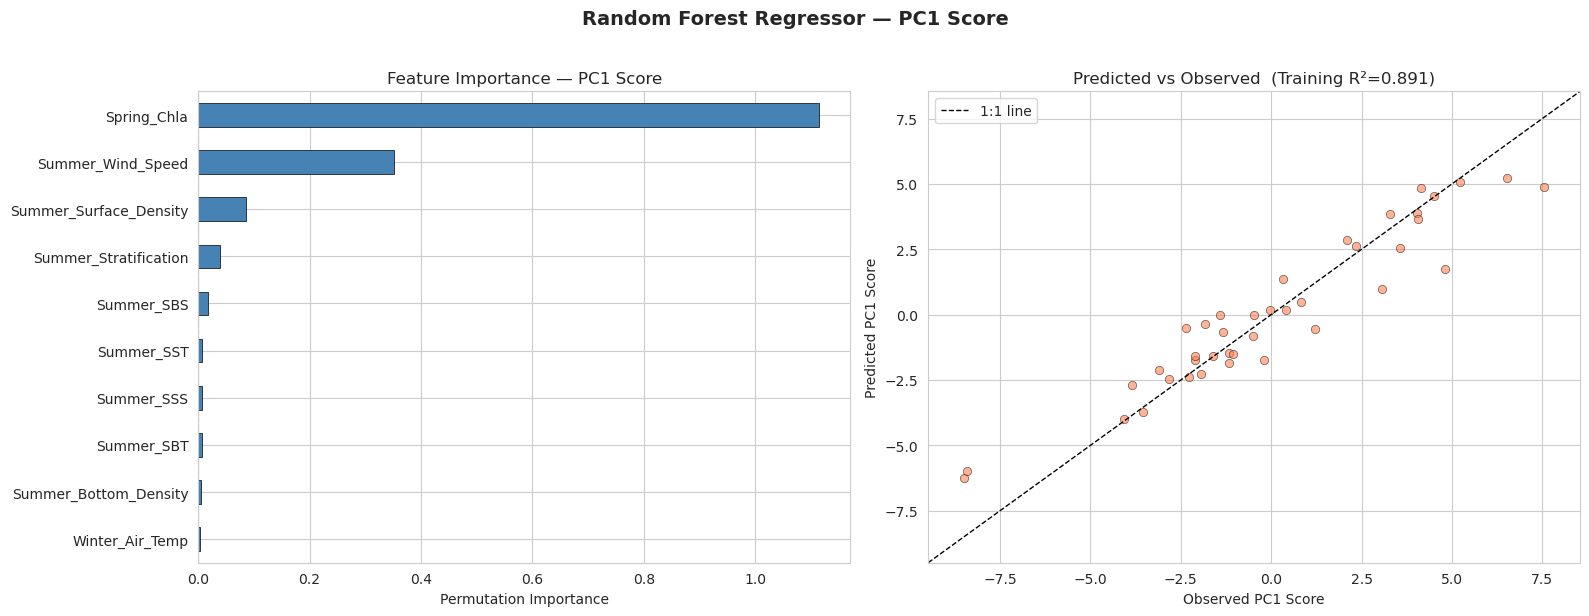

In [9]:
def run_random_forest(yearly_features, target_series, param_names, target_name):
    """
    Train a Random Forest to predict a PC score from yearly parameter features.
    Mirrors the RF analysis in Notebook 32.
    """
    # Prepare data — drop rows with NaN
    model_df = yearly_features.copy()
    model_df['target'] = target_series
    model_df = model_df.dropna()
    
    X = model_df[param_names]
    y = model_df['target']
    
    print(f"\n{'=' * 70}")
    print(f"Random Forest: Predicting {target_name} from Environmental Parameters")
    print(f"{'=' * 70}")
    print(f"Samples used (after dropping NaN): {len(X)} / {len(yearly_features)}")
    print(f"Features: {X.shape[1]}")
    
    if len(X) < 10:
        print("⚠️  Too few samples for reliable RF. Showing results with caution.")
    
    # Train Random Forest
    rf = RandomForestRegressor(
        n_estimators=500,
        max_depth=None,
        min_samples_split=5,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1,
    )
    rf.fit(X, y)
    
    # Cross-Validation (Leave-One-Out)
    loo = LeaveOneOut()
    cv_scores = cross_val_score(rf, X, y, cv=loo, scoring='r2')
    cv_rmse = cross_val_score(rf, X, y, cv=loo, scoring='neg_root_mean_squared_error')
    
    print(f"\nTraining R²:          {rf.score(X, y):.4f}")
    print(f"LOO-CV R² (mean±std): {cv_scores.mean():.4f} ± {cv_scores.std():.4f}")
    print(f"LOO-CV RMSE (mean):   {-cv_rmse.mean():.4f}")
    print("=" * 70)
    
    # Feature Importance (MDI + Permutation)
    mdi_importance = pd.Series(rf.feature_importances_, index=param_names, name='MDI_Importance')
    perm_result = permutation_importance(rf, X, y, n_repeats=30, random_state=42, n_jobs=-1)
    perm_importance = pd.Series(perm_result.importances_mean, index=param_names, name='Permutation_Importance')
    
    importance_df = pd.DataFrame({
        'MDI_Importance': mdi_importance,
        'Permutation_Importance': perm_importance,
    }).sort_values('Permutation_Importance', ascending=False)
    
    print("\nFeature Importance Ranking:")
    display(importance_df)
    
    # Visualization
    fig, axes = plt.subplots(1, 2, figsize=(16, 6))
    
    # (a) Feature importance bar chart
    importance_df['Permutation_Importance'].sort_values().plot.barh(
        ax=axes[0], color='steelblue', edgecolor='black', linewidth=0.5
    )
    axes[0].set_xlabel('Permutation Importance')
    axes[0].set_title(f'Feature Importance — {target_name}')
    axes[0].axvline(x=0, color='grey', linestyle='--', linewidth=0.8)
    
    # (b) Predicted vs Observed
    y_pred = rf.predict(X)
    axes[1].scatter(y, y_pred, alpha=0.6, edgecolors='black', linewidth=0.5, color='coral')
    lims = [min(y.min(), y_pred.min()) - 1, max(y.max(), y_pred.max()) + 1]
    axes[1].plot(lims, lims, 'k--', linewidth=1, label='1:1 line')
    axes[1].set_xlabel(f'Observed {target_name}')
    axes[1].set_ylabel(f'Predicted {target_name}')
    axes[1].set_title(f'Predicted vs Observed  (Training R²={rf.score(X, y):.3f})')
    axes[1].legend()
    axes[1].set_xlim(lims)
    axes[1].set_ylim(lims)
    
    plt.suptitle(f'Random Forest Regressor — {target_name}', fontsize=14, fontweight='bold', y=1.02)
    plt.tight_layout()
    plt.show()
    
    return rf, importance_df


# Run RF for PC1
rf_pc1, imp_pc1 = run_random_forest(yearly_features, pca_scores['PC1'], param_names, 'PC1 Score')


Random Forest: Predicting PC2 Score from Environmental Parameters
Samples used (after dropping NaN): 40 / 41
Features: 10

Training R²:          0.7408
LOO-CV R² (mean±std): nan ± nan
LOO-CV RMSE (mean):   2.1487

Feature Importance Ranking:


,MDI_Importance,Permutation_Importance
Summer_Stratification,0.286364,0.367182
Summer_SST,0.177625,0.123284
Summer_Wind_Speed,0.102041,0.080936
Summer_SBT,0.088482,0.072523
Spring_Chla,0.079038,0.065080
Winter_Air_Temp,0.068055,0.052204
Summer_Bottom_Density,0.067634,0.041404
Summer_SBS,0.048879,0.036117
Summer_SSS,0.040295,0.024787
Summer_Surface_Density,0.041587,0.023811


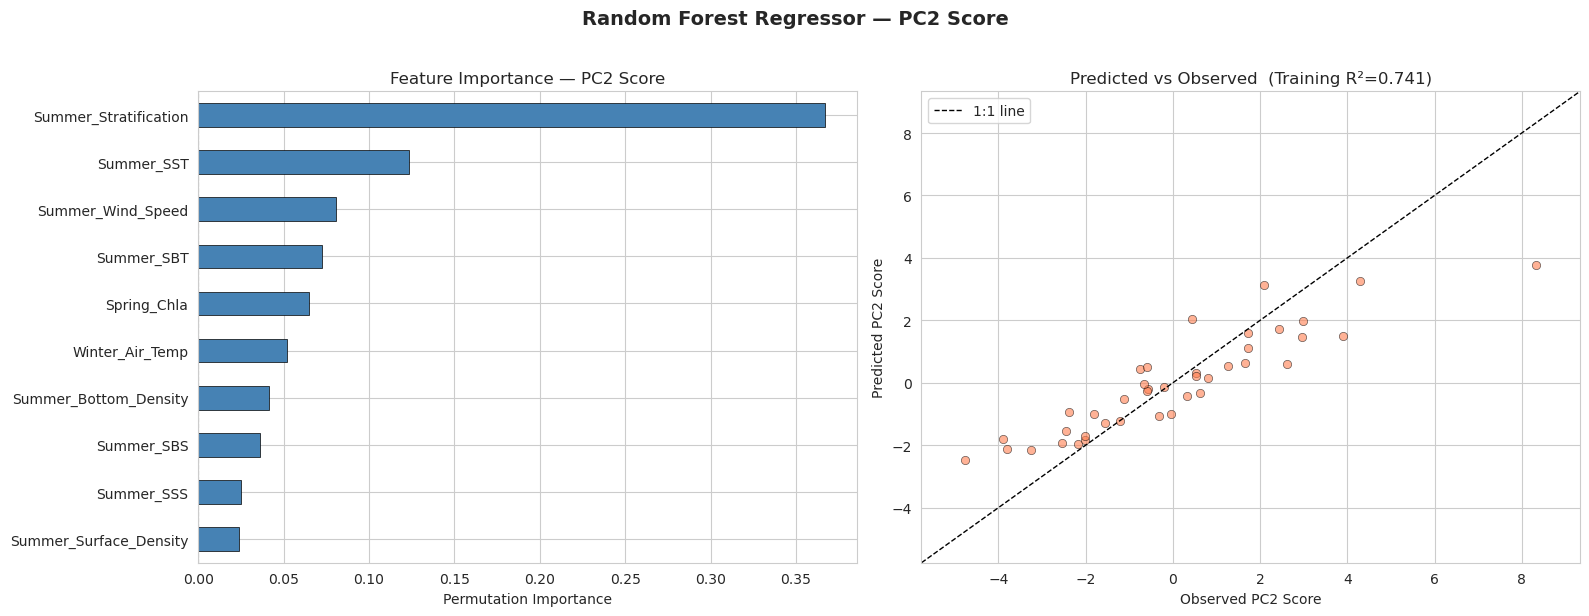

In [10]:
# Run RF for PC2
rf_pc2, imp_pc2 = run_random_forest(yearly_features, pca_scores['PC2'], param_names, 'PC2 Score')

## 7. Visualization: Per-Station Correlation Heatmaps

Visualize the per-station correlations as heatmaps and bar charts to identify 
which parameters have the strongest relationships with PC1 and PC2.

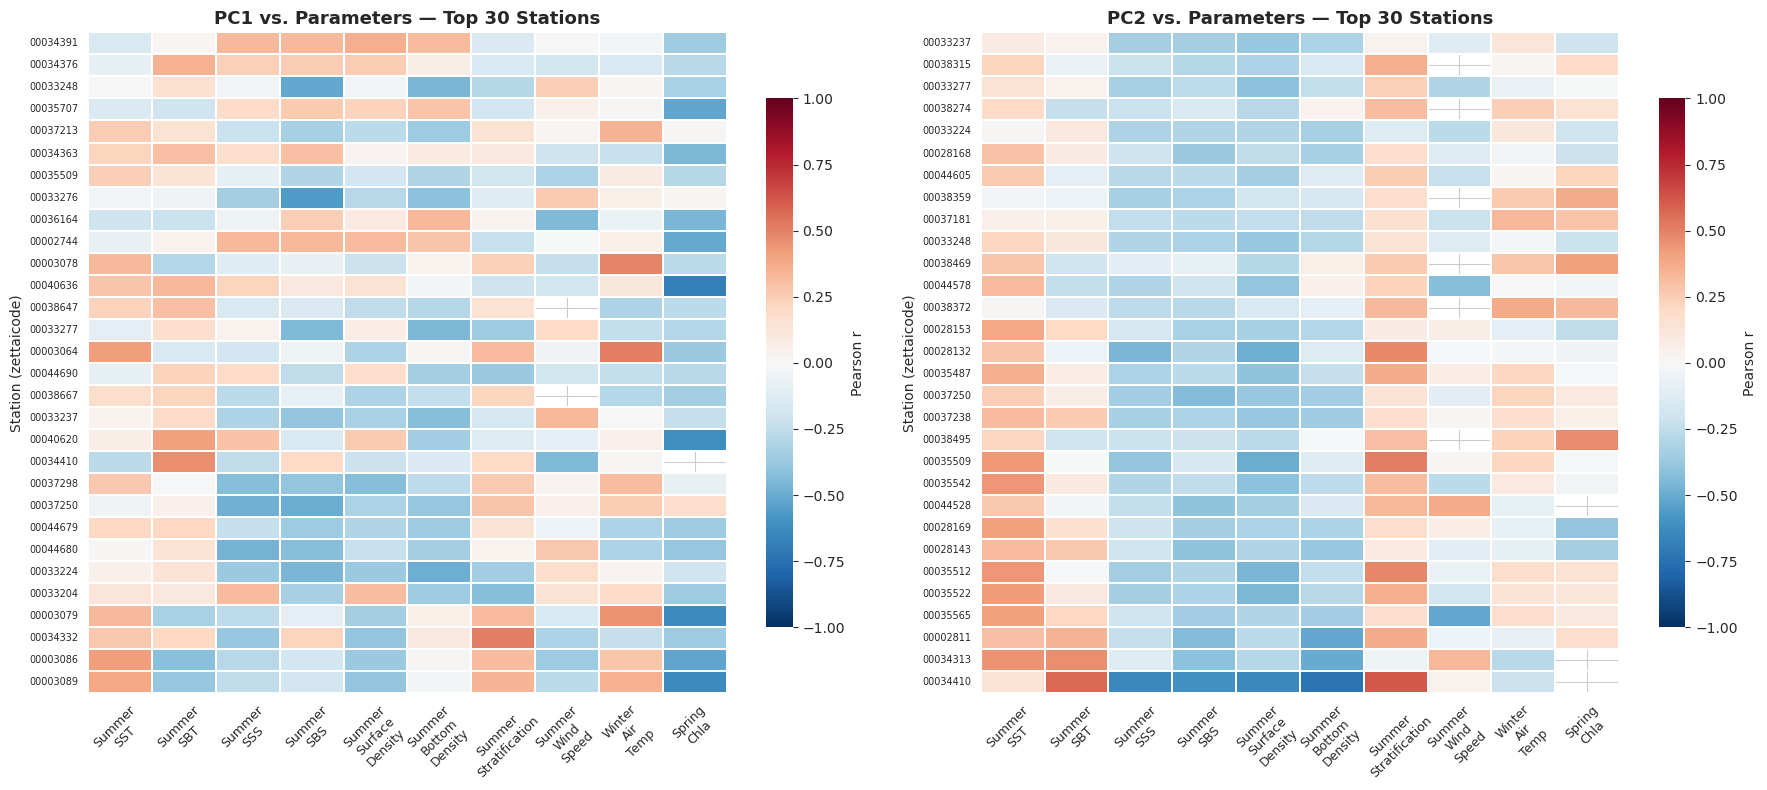

In [11]:
# Heatmap: Mean correlation by parameter for PC1 and PC2
fig, axes = plt.subplots(1, 2, figsize=(18, 8))

for ax, corr_df, pc_name in zip(axes, [corr_df_pc1, corr_df_pc2], ['PC1', 'PC2']):
    # Sort stations by mean absolute correlation for better visualization
    mean_abs = corr_df.abs().mean(axis=1)
    sorted_idx = mean_abs.sort_values(ascending=True).index
    
    # Only show top 30 stations for readability
    top_stations = sorted_idx[-30:]
    plot_data = corr_df.loc[top_stations]
    
    sns.heatmap(
        plot_data,
        ax=ax,
        cmap='RdBu_r',
        center=0,
        vmin=-1, vmax=1,
        linewidths=0.3,
        cbar_kws={'label': 'Pearson r', 'shrink': 0.8},
        xticklabels=[n.replace('_', '\n') for n in param_names],
        yticklabels=True
    )
    ax.set_title(f'{pc_name} vs. Parameters — Top 30 Stations', fontsize=13, fontweight='bold')
    ax.set_ylabel('Station (zettaicode)')
    ax.tick_params(axis='x', rotation=45, labelsize=9)
    ax.tick_params(axis='y', labelsize=7)

plt.tight_layout()
plt.savefig(ProjectPaths.FIGURES_DIR / 'pc_param_correlation_heatmaps.png', 
            bbox_inches='tight', dpi=150)
plt.show()

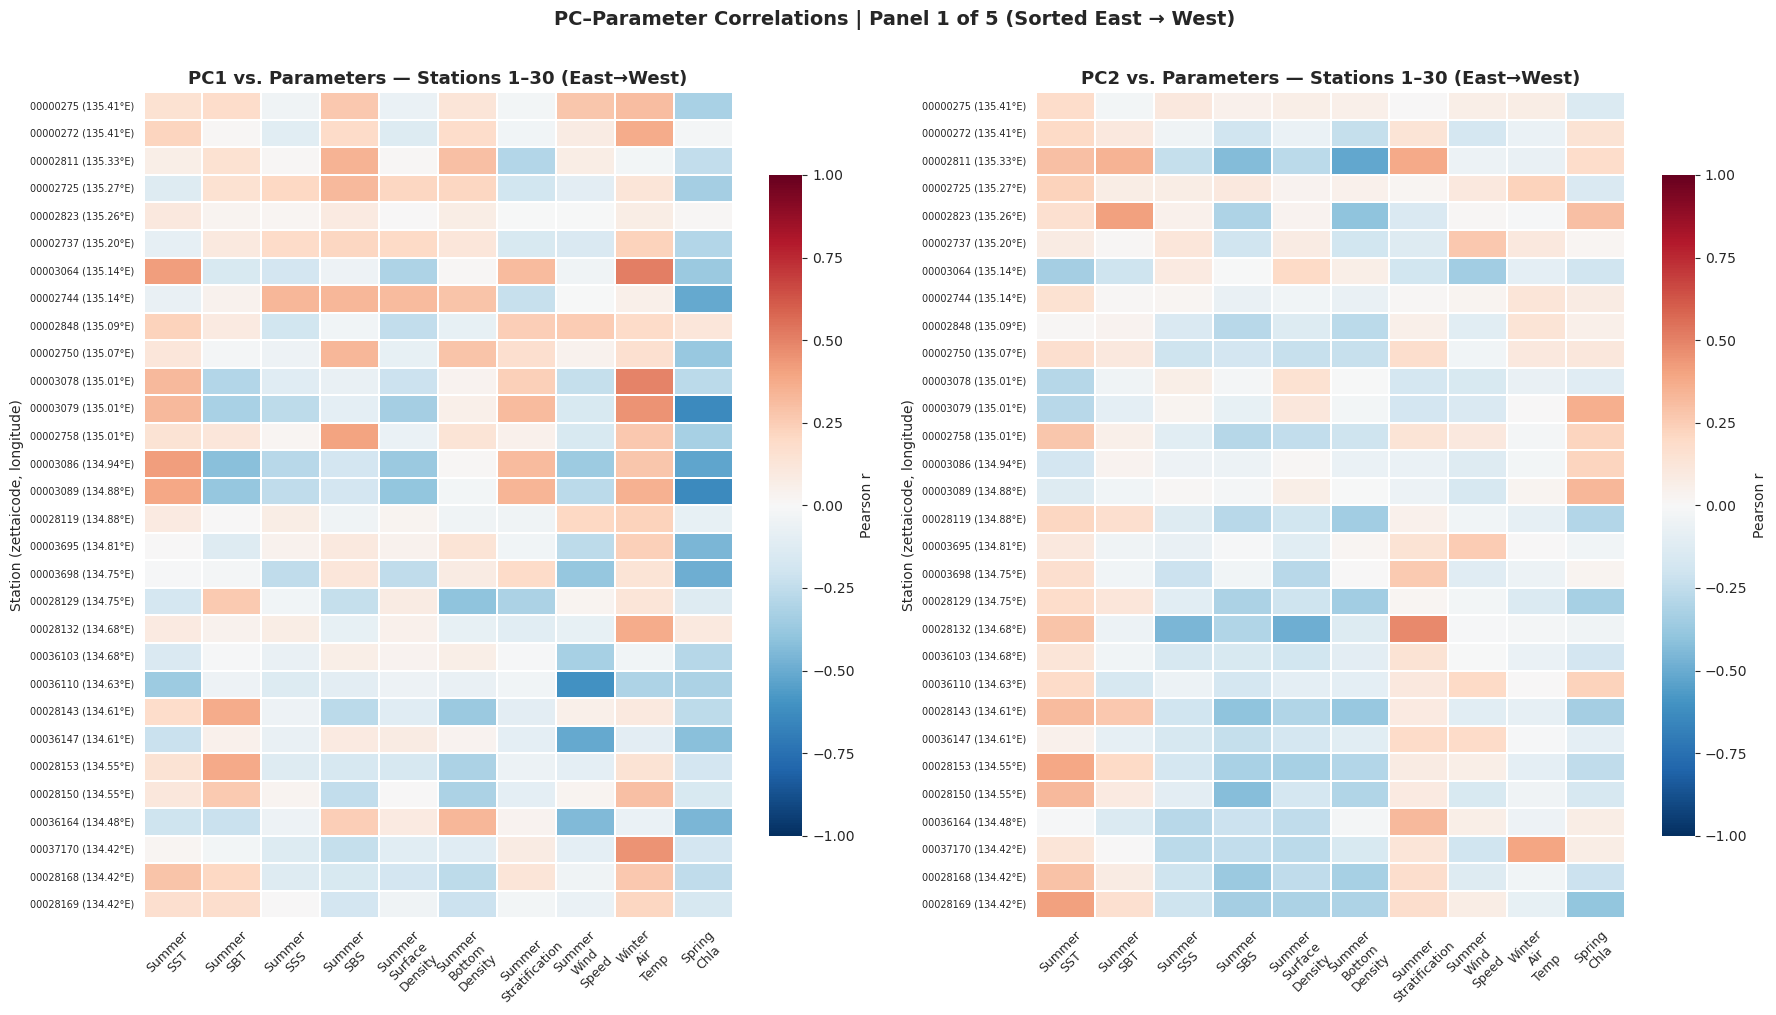

Saved: pc_param_correlation_heatmaps_panel1.png


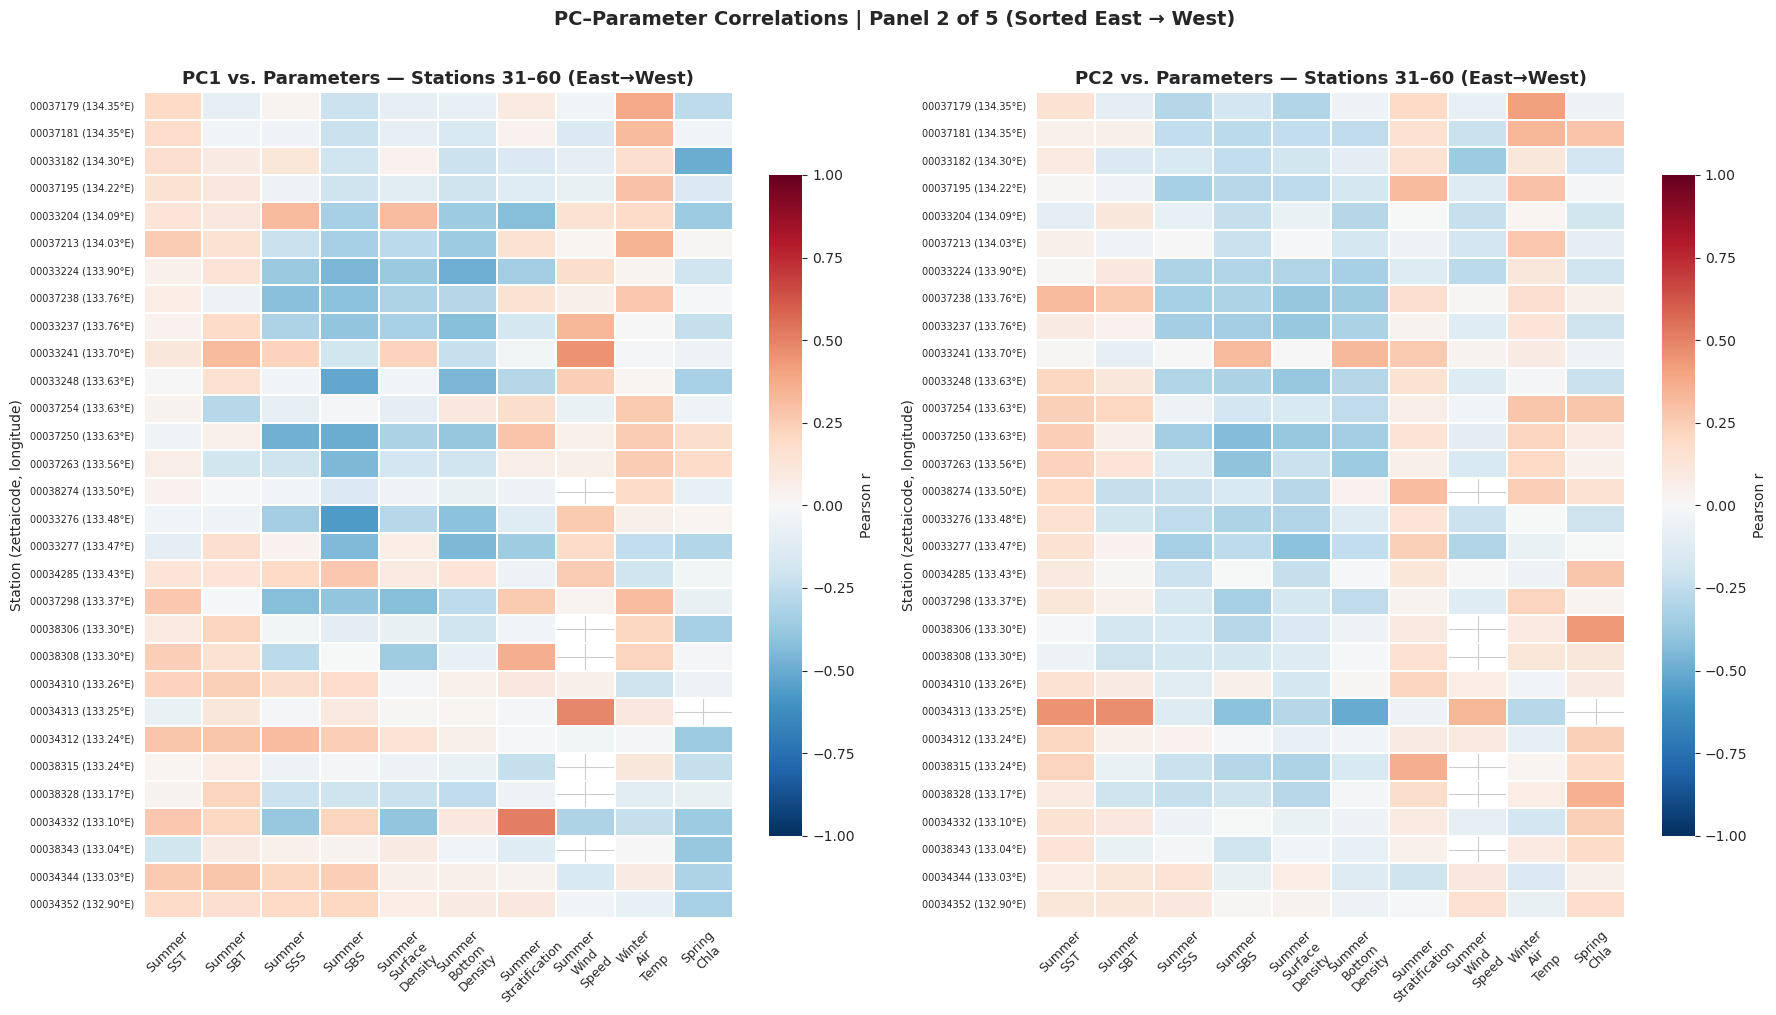

Saved: pc_param_correlation_heatmaps_panel2.png


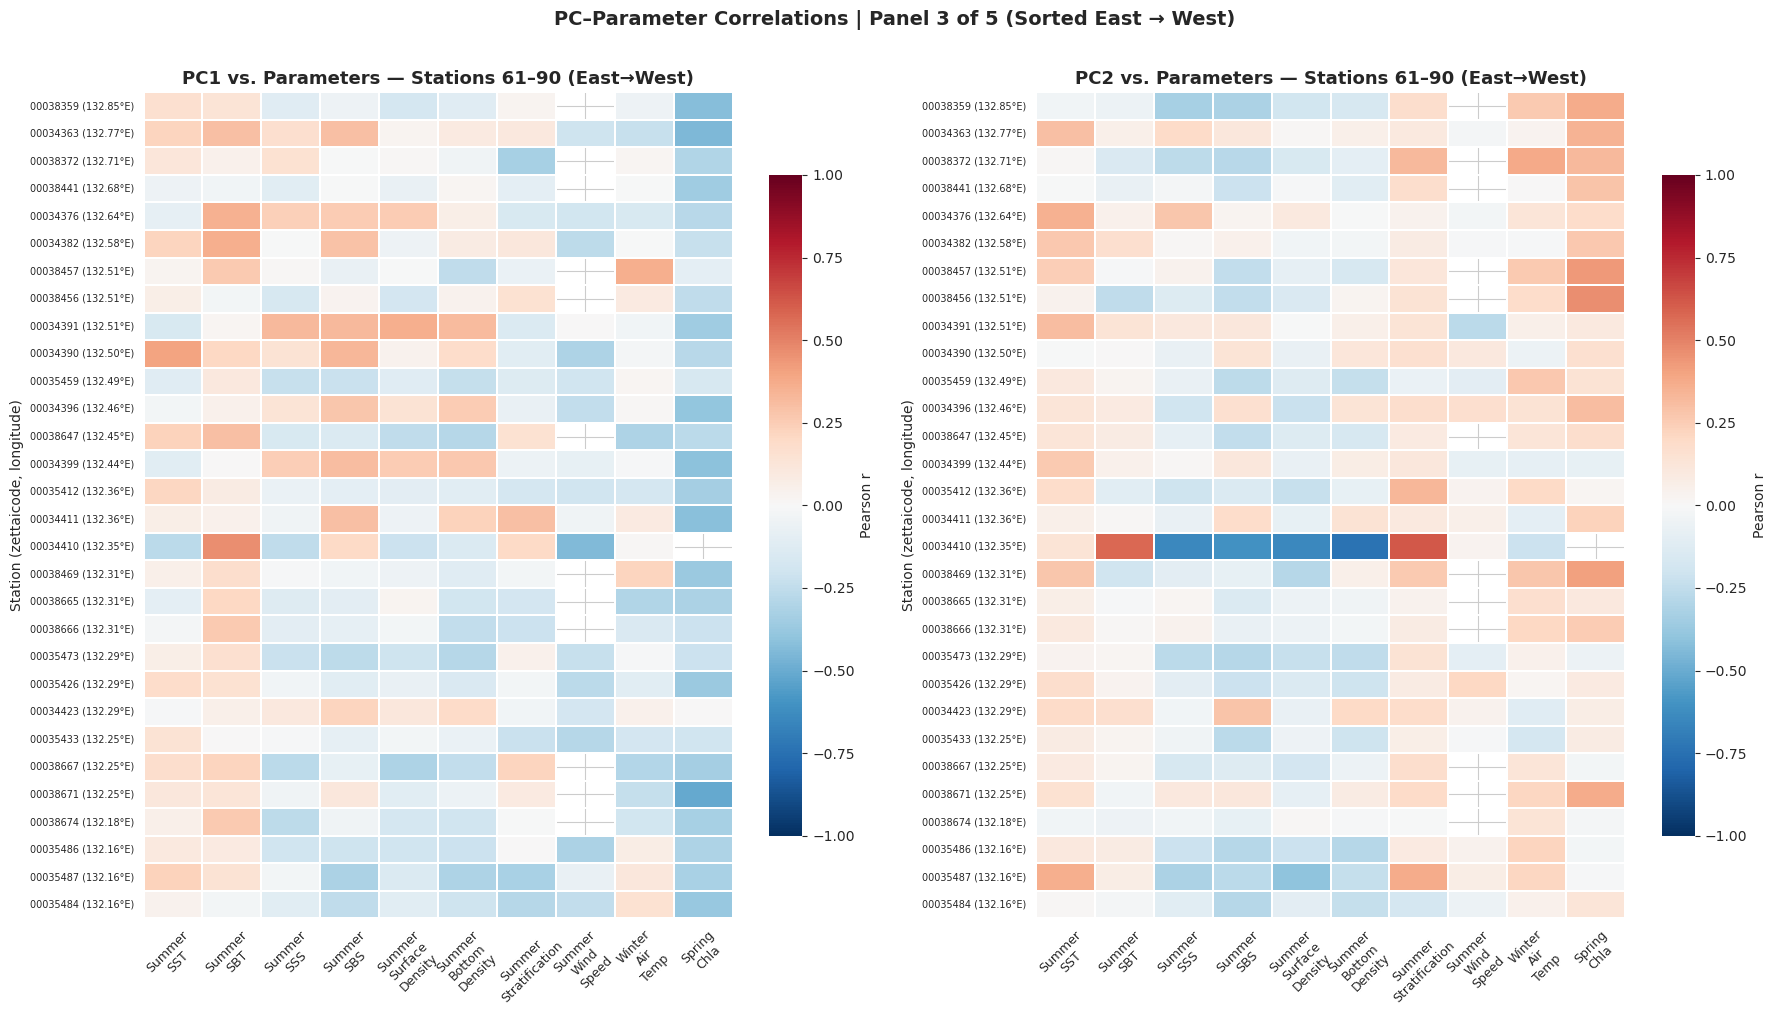

Saved: pc_param_correlation_heatmaps_panel3.png


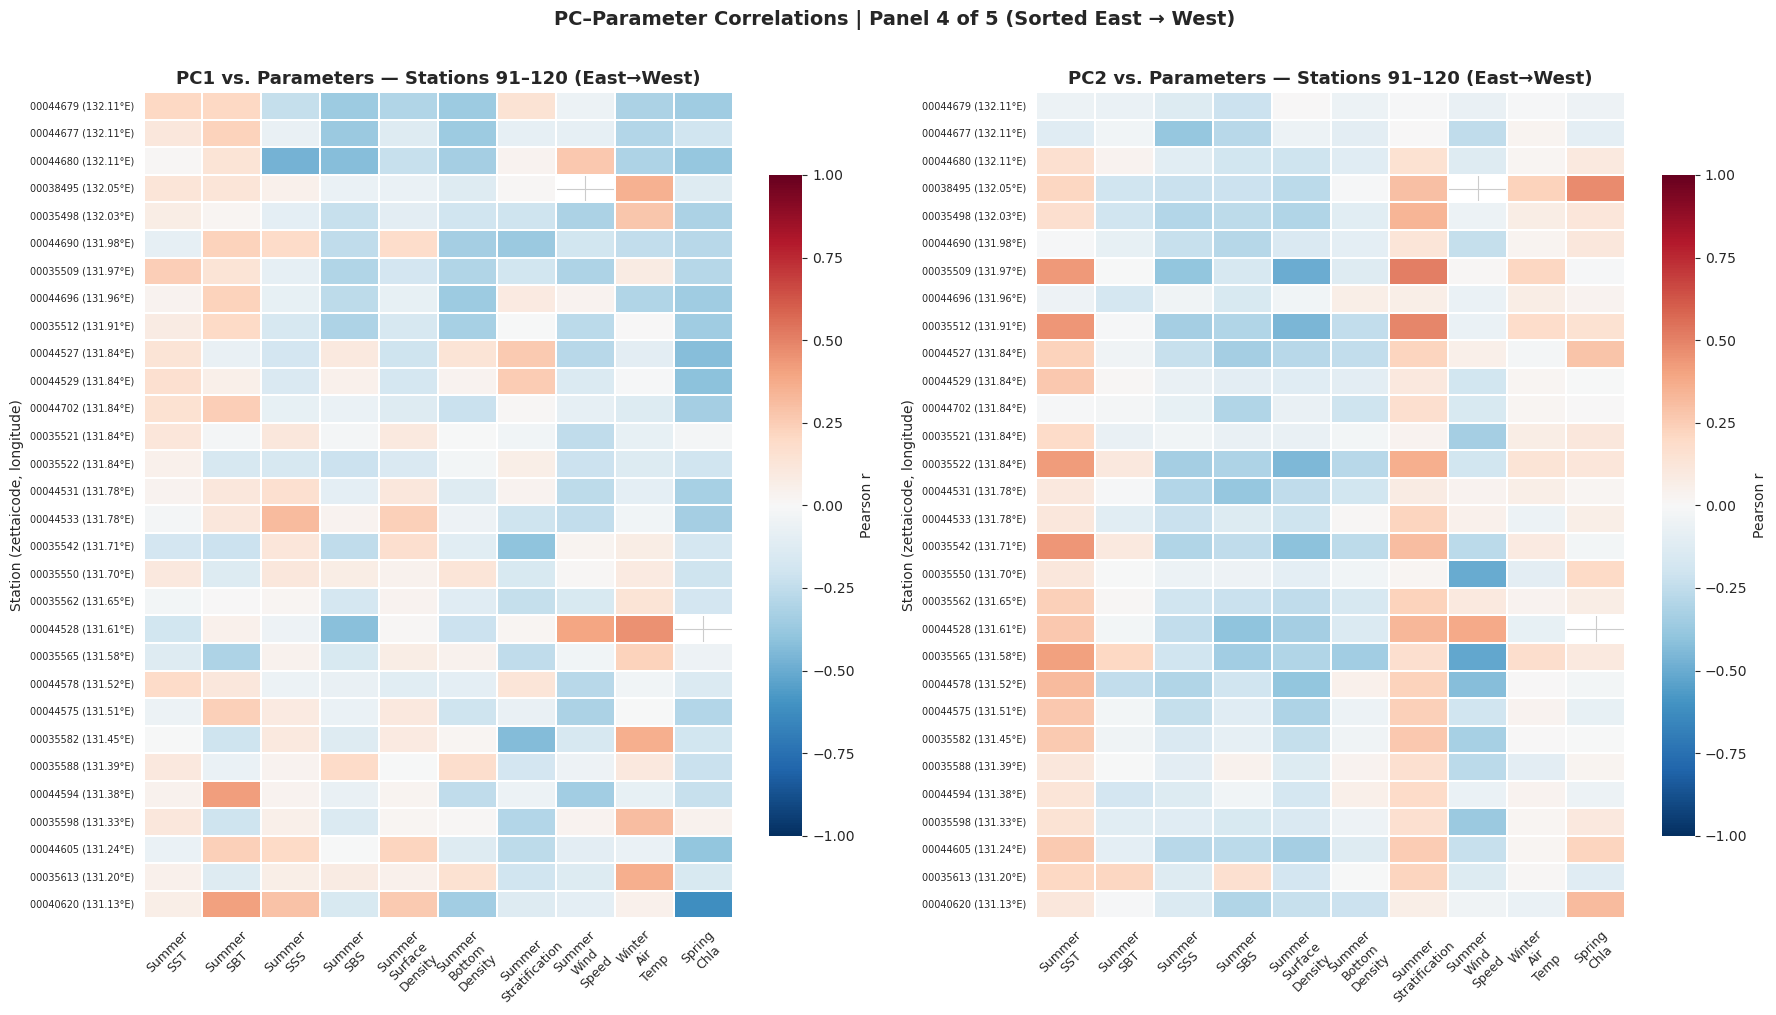

Saved: pc_param_correlation_heatmaps_panel4.png


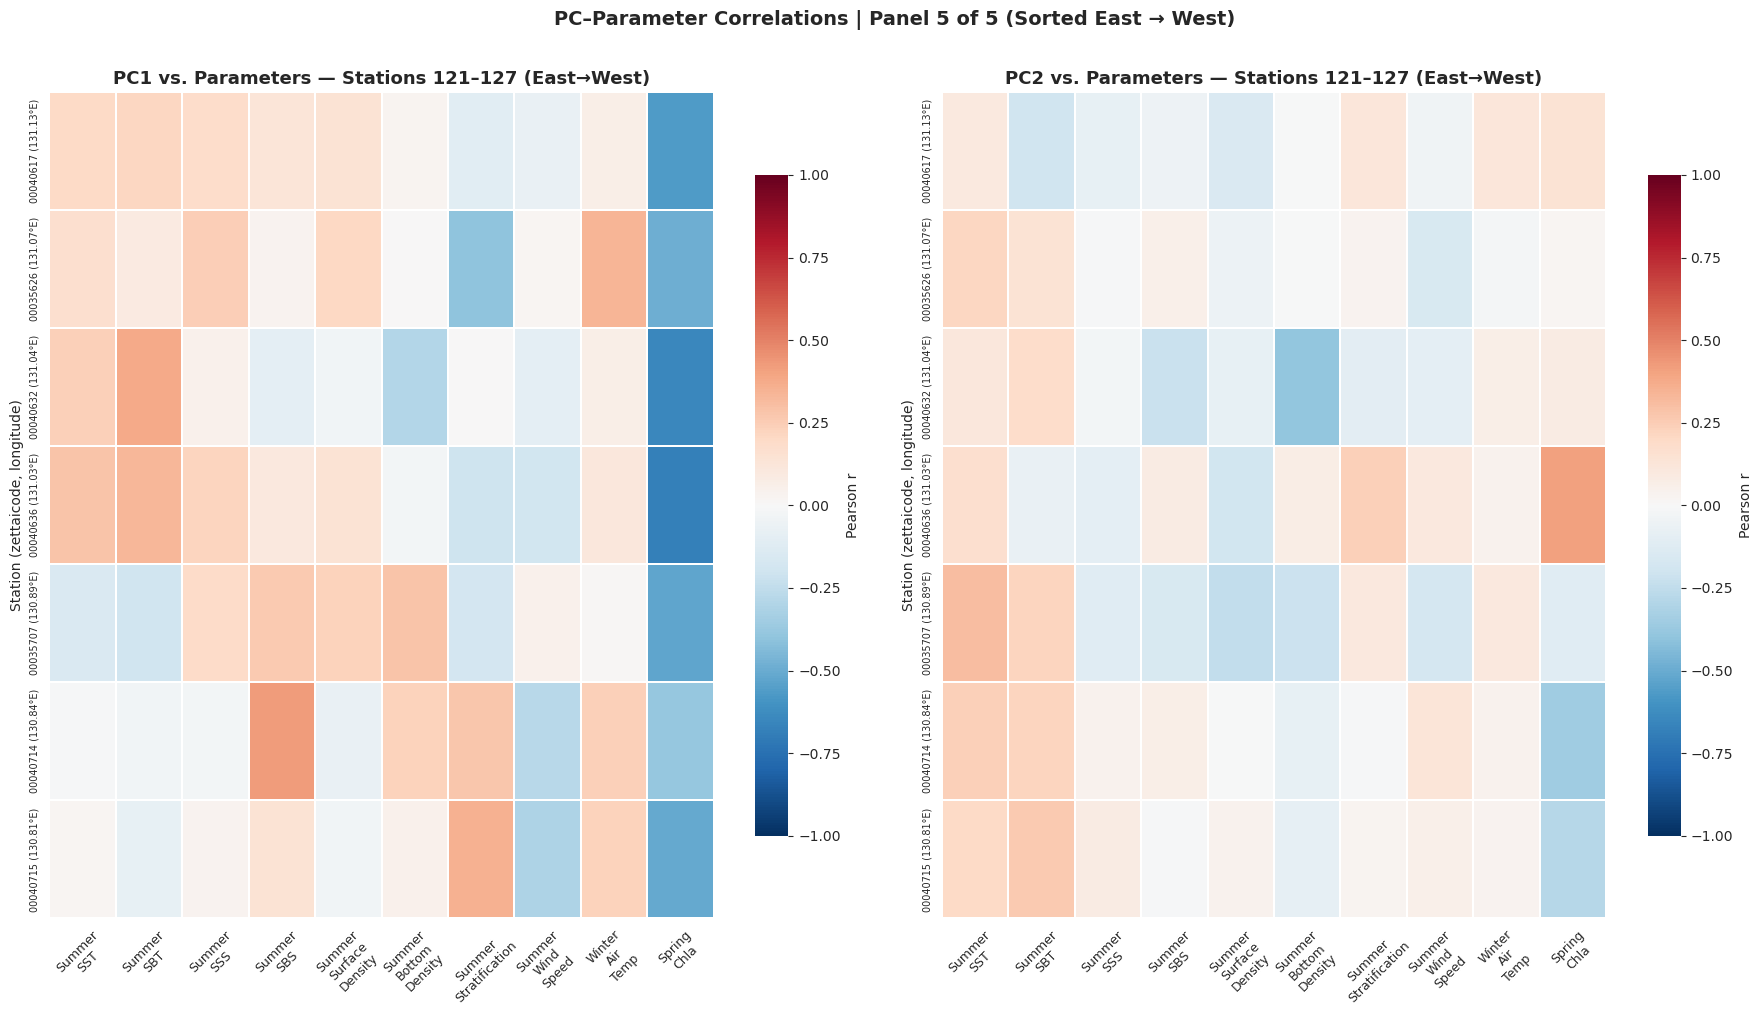

Saved: pc_param_correlation_heatmaps_panel5.png


In [12]:
# Heatmap: All stations split into 5 panels of 30, sorted East → West by longitude

# --- 1. Sort all stations by longitude descending (East → West) ---
# Only keep stations that appear in either corr_df
all_station_idx = corr_df_pc1.index.union(corr_df_pc2.index)

# Look up longitude for each station and sort descending (east first)
station_lon = stations.loc[
    stations.index.intersection(all_station_idx), 'longitude'
]
sorted_stations = station_lon.sort_values(ascending=False).index.tolist()

# --- 2. Chunk into groups of 30 ---
CHUNK_SIZE = 30
chunks = [sorted_stations[i:i + CHUNK_SIZE] for i in range(0, len(sorted_stations), CHUNK_SIZE)]

# --- 3. Plot one figure per chunk ---
for panel_idx, chunk in enumerate(chunks):
    fig, axes = plt.subplots(1, 2, figsize=(18, 10))

    for ax, corr_df, pc_name in zip(axes, [corr_df_pc1, corr_df_pc2], ['PC1', 'PC2']):
        # Select only stations in this chunk that exist in the corr_df
        present = [s for s in chunk if s in corr_df.index]
        plot_data = corr_df.loc[present]

        sns.heatmap(
            plot_data,
            ax=ax,
            cmap='RdBu_r',
            center=0,
            vmin=-1, vmax=1,
            linewidths=0.3,
            cbar_kws={'label': 'Pearson r', 'shrink': 0.8},
            xticklabels=[n.replace('_', '\n') for n in param_names],
            yticklabels=True
        )

        # Annotate each station label with its longitude for reference
        ytick_labels = []
        for stn in present:
            lon_val = station_lon.get(stn, float('nan'))
            ytick_labels.append(f"{stn} ({lon_val:.2f}°E)")
        ax.set_yticklabels(ytick_labels, fontsize=7)

        start_rank = panel_idx * CHUNK_SIZE + 1
        end_rank   = start_rank + len(present) - 1
        ax.set_title(
            f'{pc_name} vs. Parameters — Stations {start_rank}–{end_rank} (East→West)',
            fontsize=13, fontweight='bold'
        )
        ax.set_ylabel('Station (zettaicode, longitude)')
        ax.tick_params(axis='x', rotation=45, labelsize=9)
        ax.tick_params(axis='y', labelsize=7)

    plt.suptitle(
        f'PC–Parameter Correlations | Panel {panel_idx + 1} of {len(chunks)} '
        f'(Sorted East → West)',
        fontsize=14, fontweight='bold', y=1.01
    )
    plt.tight_layout()

    save_path = ProjectPaths.FIGURES_DIR / f'pc_param_correlation_heatmaps_panel{panel_idx + 1}.png'
    plt.savefig(save_path, bbox_inches='tight', dpi=150)
    plt.show()
    print(f"Saved: {save_path.name}")


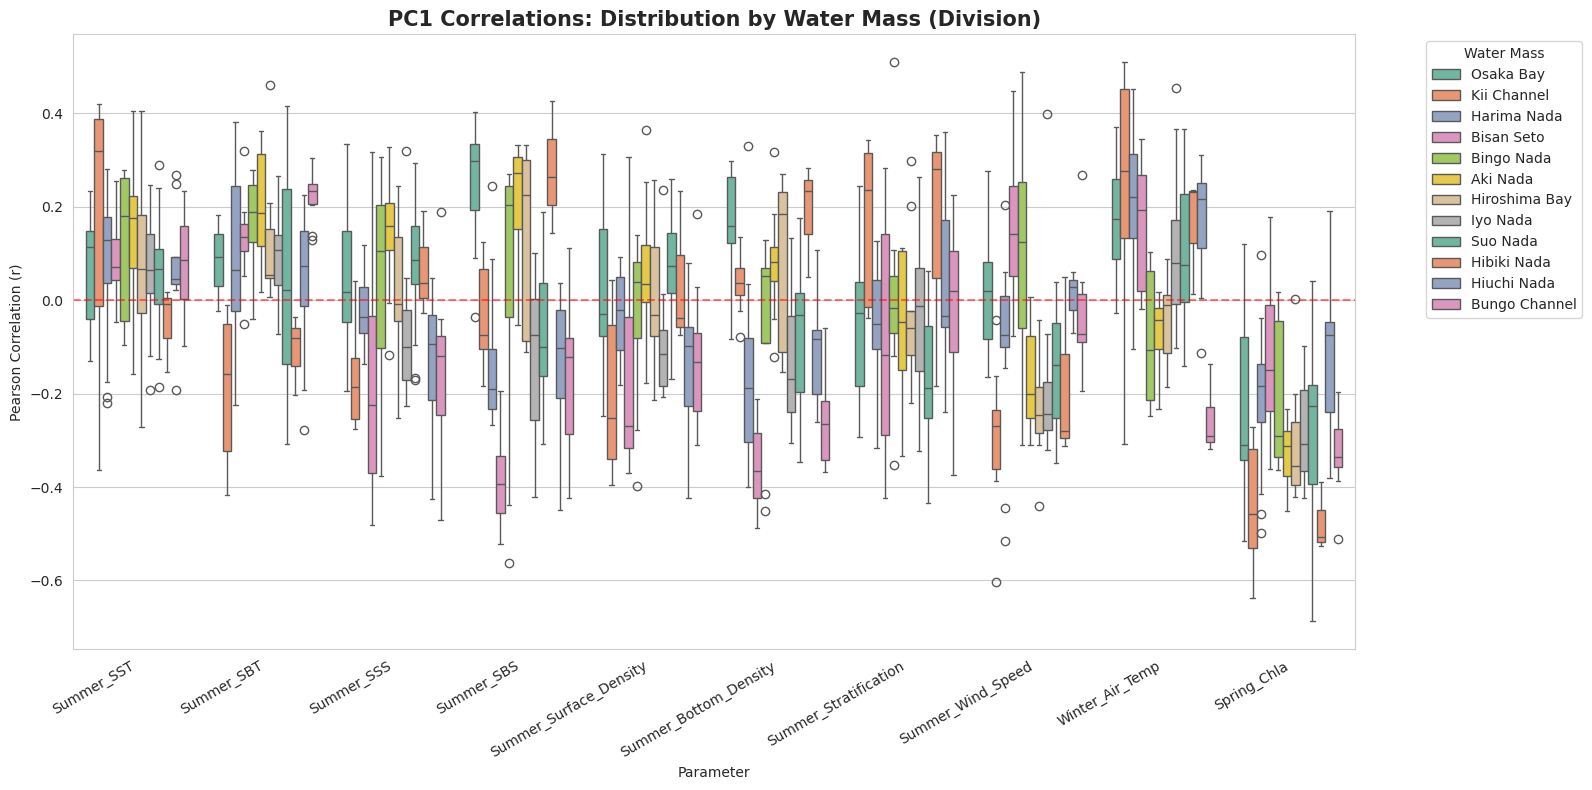

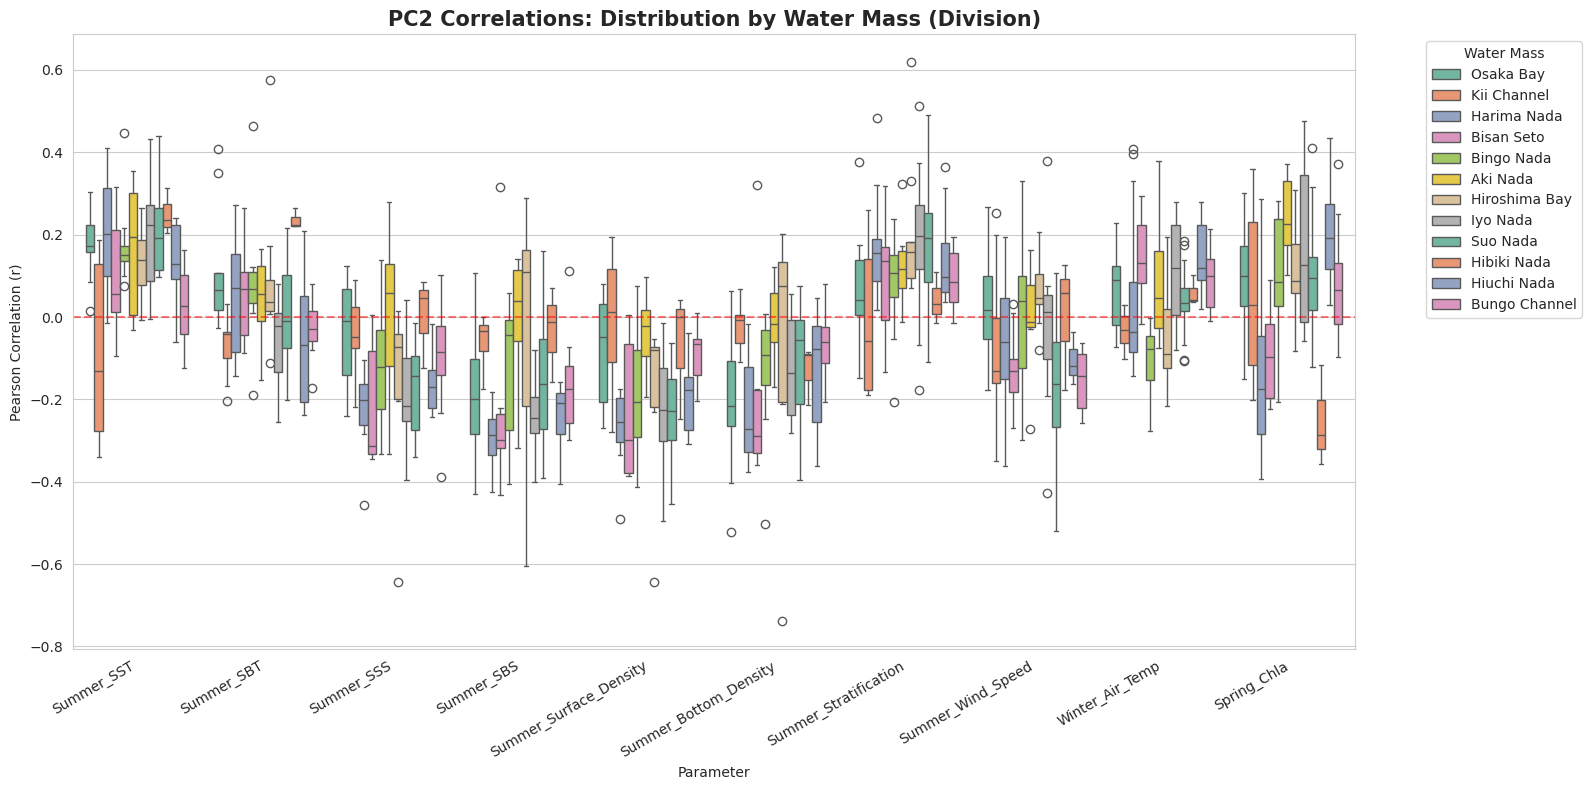

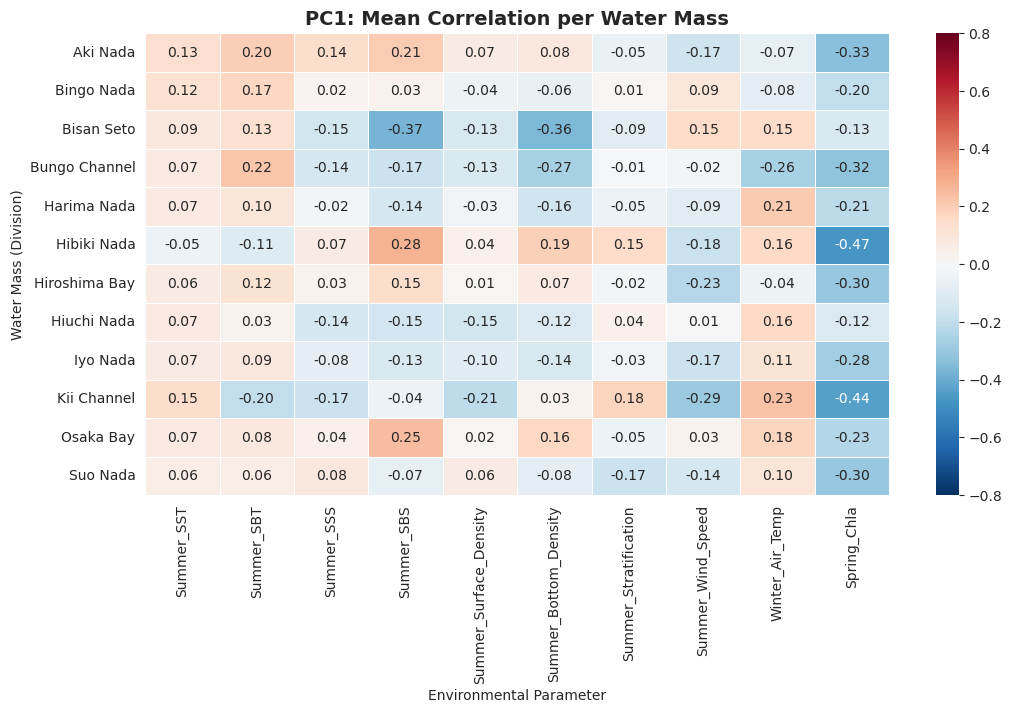

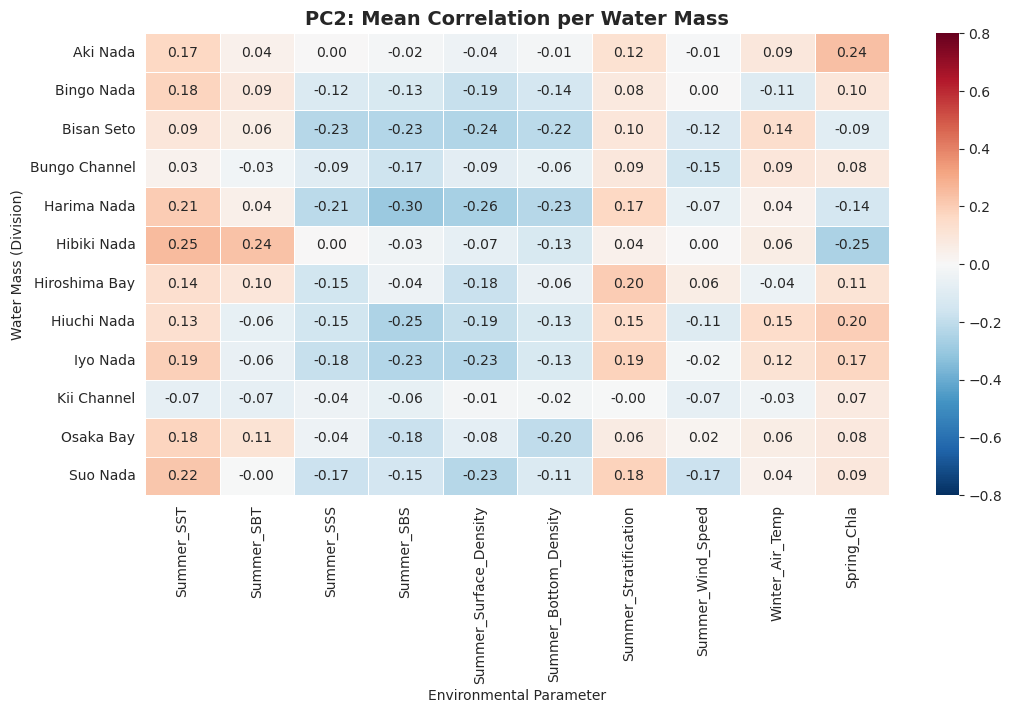

In [13]:
# --- 1. Extract Division Mapping ---
# Extract unique zettaicode -> division mapping from the merged data
# (If your variable is named 'merged_gdf', change 'merged_df' to 'merged_gdf')
stn_division = merged_df[['zettaicode', 'division']].drop_duplicates().set_index('zettaicode')

# Join divisions with the correlation results
corr_div_pc1 = corr_df_pc1.join(stn_division)
corr_div_pc2 = corr_df_pc2.join(stn_division)

# --- 2. Boxplot: Variation of Effects by Division ---
def plot_division_boxplots(df, pc_name):
    """Plots the distribution of correlations per parameter, split by division."""
    melted = df.melt(id_vars='division', var_name='Parameter', value_name='Pearson r')
    
    plt.figure(figsize=(16, 8))
    sns.boxplot(data=melted, x='Parameter', y='Pearson r', hue='division', palette='Set2')
    
    plt.title(f'{pc_name} Correlations: Distribution by Water Mass (Division)', fontsize=15, fontweight='bold')
    plt.axhline(0, color='red', linestyle='--', alpha=0.5)
    plt.xticks(rotation=30, ha='right')
    plt.ylabel('Pearson Correlation (r)')
    plt.legend(title='Water Mass', bbox_to_anchor=(1.05, 1), loc='upper left')
    plt.tight_layout()
    plt.show()

# Visualize the spread for both PCs
plot_division_boxplots(corr_div_pc1, 'PC1')
plot_division_boxplots(corr_div_pc2, 'PC2')

# --- 3. Summary Heatmap: Mean Effect per Division ---
def plot_mean_division_heatmap(df, pc_name):
    """Plots a heatmap of the average correlation coefficient for each division."""
    mean_corr = df.groupby('division').mean()
    
    plt.figure(figsize=(12, 6))
    sns.heatmap(mean_corr, cmap='RdBu_r', center=0, vmin=-0.8, vmax=0.8, 
                annot=True, fmt=".2f", linewidths=0.5)
    
    plt.title(f'{pc_name}: Mean Correlation per Water Mass', fontsize=14, fontweight='bold')
    plt.ylabel('Water Mass (Division)')
    plt.xlabel('Environmental Parameter')
    plt.show()

plot_mean_division_heatmap(corr_div_pc1, 'PC1')
plot_mean_division_heatmap(corr_div_pc2, 'PC2')

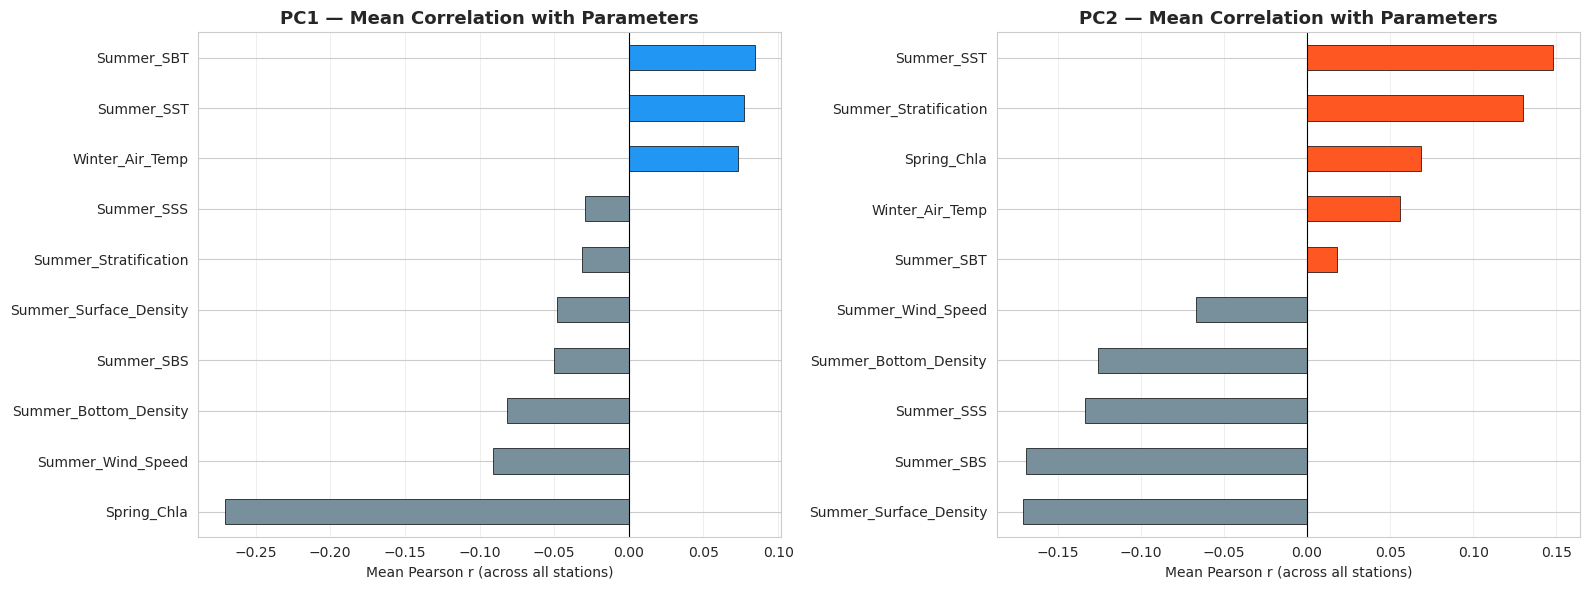

In [14]:
# Bar chart: Mean correlation across all stations for each parameter
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

for ax, corr_df, pc_name, color in zip(axes, [corr_df_pc1, corr_df_pc2], ['PC1', 'PC2'], ['#2196F3', '#FF5722']):
    means = corr_df.mean().sort_values()
    colors = [color if v >= 0 else '#78909C' for v in means.values]
    
    means.plot.barh(ax=ax, color=colors, edgecolor='black', linewidth=0.5)
    ax.set_xlabel('Mean Pearson r (across all stations)')
    ax.set_title(f'{pc_name} — Mean Correlation with Parameters', fontsize=13, fontweight='bold')
    ax.axvline(x=0, color='black', linestyle='-', linewidth=0.8)
    ax.grid(axis='x', alpha=0.3)

plt.tight_layout()
plt.savefig(ProjectPaths.FIGURES_DIR / 'pc_param_mean_correlation_bars.png', 
            bbox_inches='tight', dpi=150)
plt.show()

## 8. Distribution of Per-Station Correlations

Box plots showing the distribution of correlation values across all stations for each parameter.

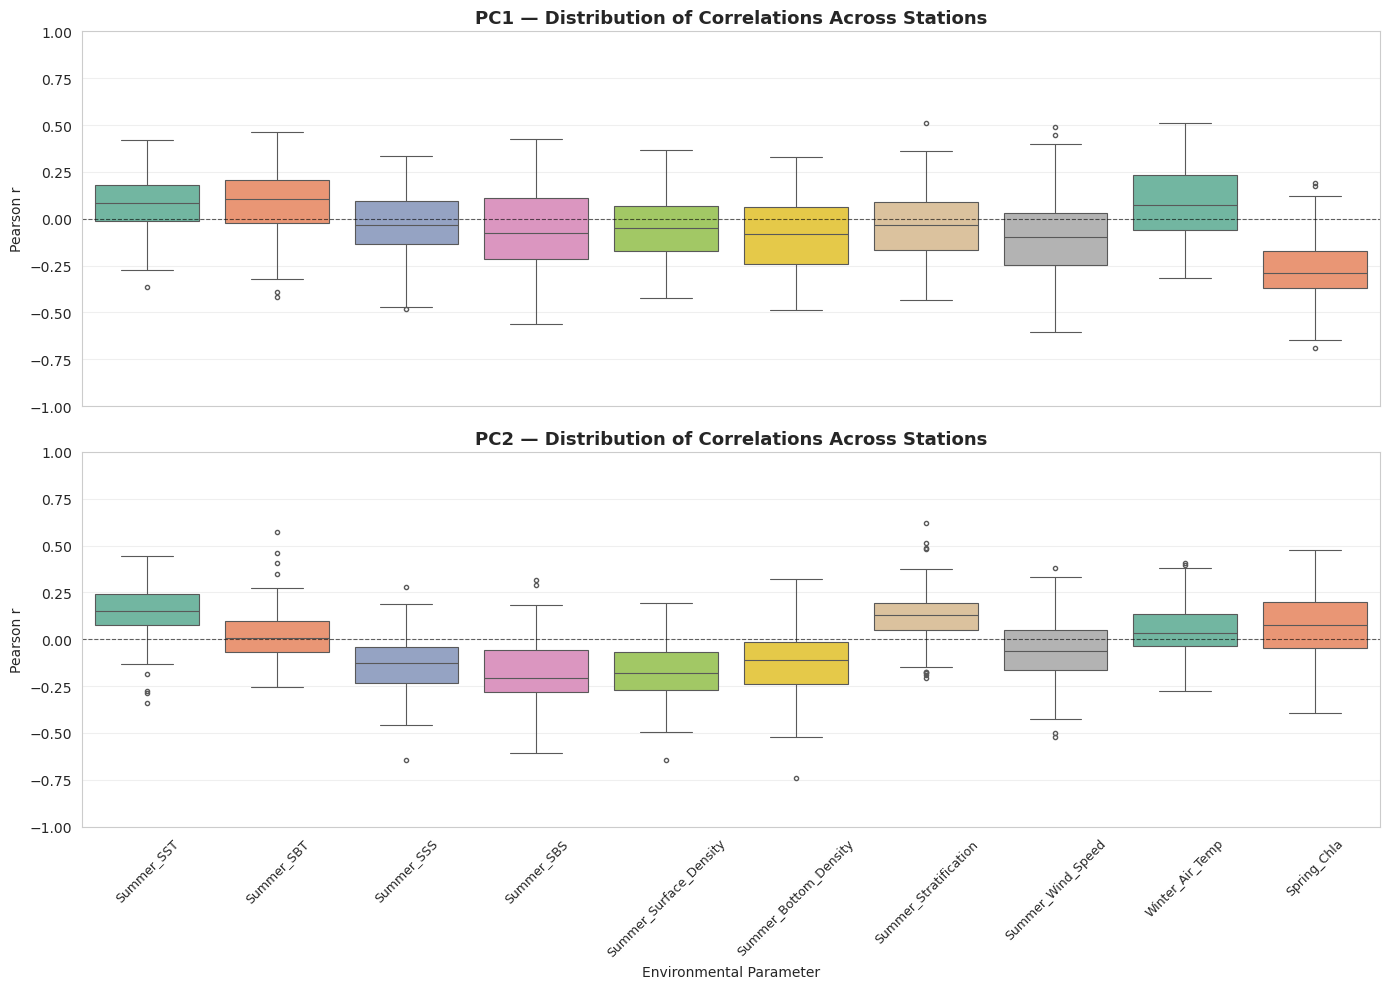

In [15]:
fig, axes = plt.subplots(2, 1, figsize=(14, 10), sharex=True)

for ax, corr_df, pc_name in zip(axes, [corr_df_pc1, corr_df_pc2], ['PC1', 'PC2']):
    # Melt for seaborn
    melted = corr_df.melt(var_name='Parameter', value_name='Pearson_r')
    
    sns.boxplot(
        data=melted, x='Parameter', y='Pearson_r',
        ax=ax, palette='Set2', fliersize=3, linewidth=0.8
    )
    ax.axhline(y=0, color='black', linestyle='--', linewidth=0.8, alpha=0.6)
    ax.set_title(f'{pc_name} — Distribution of Correlations Across Stations', fontsize=13, fontweight='bold')
    ax.set_ylabel('Pearson r')
    ax.set_ylim(-1, 1)
    ax.tick_params(axis='x', rotation=45, labelsize=9)
    ax.grid(axis='y', alpha=0.3)

axes[-1].set_xlabel('Environmental Parameter')
plt.tight_layout()
plt.savefig(ProjectPaths.FIGURES_DIR / 'pc_param_correlation_boxplots.png', 
            bbox_inches='tight', dpi=150)
plt.show()

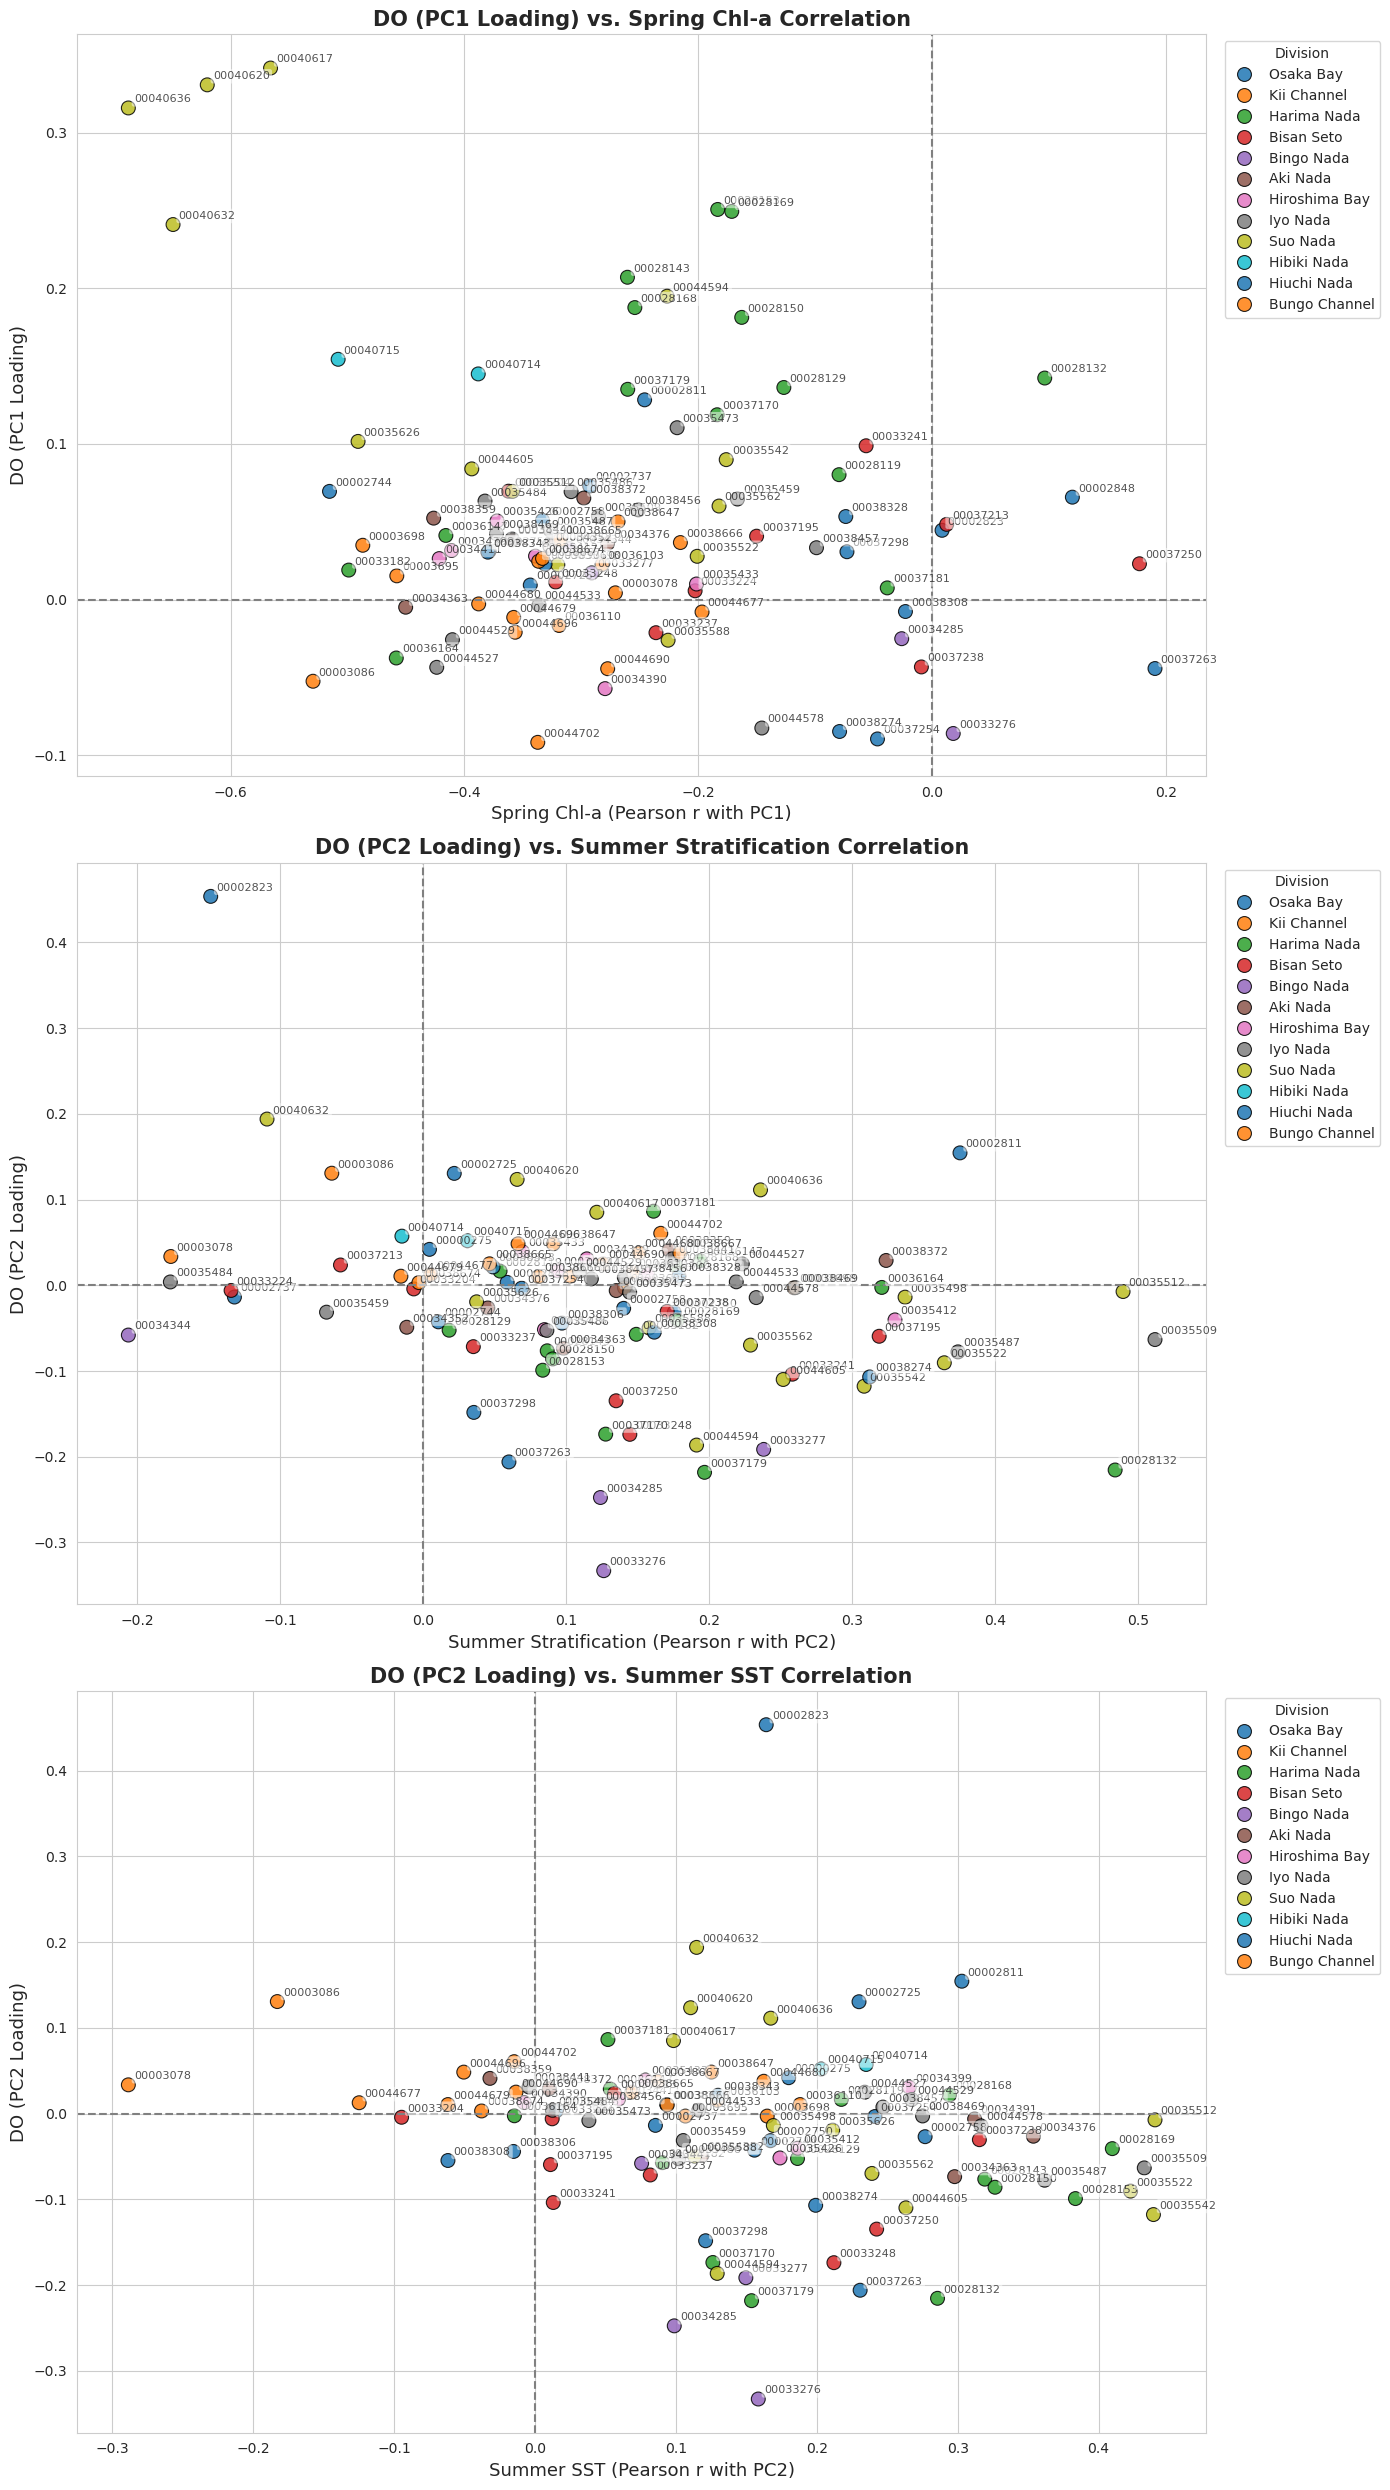

In [16]:
# 1. Load PCA Loadings representing the DO spatial pattern
pca_loadings_path = subset_dir / 'pca_loadings.csv'
pca_loadings = pd.read_csv(pca_loadings_path, dtype={'zettaicode': str}).set_index('zettaicode')

# 2. Extract Water Mass (division) per station from the merged_df
divisions = merged_df[['zettaicode', 'division']].drop_duplicates('zettaicode').set_index('zettaicode')

# 3. Create a combined DataFrame for plotting
plot_df = pd.DataFrame(index=corr_df_pc1.index)
plot_df['Spring_Chla_Corr'] = corr_df_pc1['Spring_Chla']
plot_df['Summer_Stratification_Corr'] = corr_df_pc2['Summer_Stratification']
plot_df['Summer_SST_Corr'] = corr_df_pc2['Summer_SST']

# Join the DO loadings and divisions
plot_df = plot_df.join(pca_loadings[['PC1_Loading', 'PC2_Loading']])
plot_df = plot_df.join(divisions['division'])

# 4. Generate the 3 scatterplots
fig, axes = plt.subplots(3, 1, figsize=(14, 25))

plots_config = [
    {
        'x': 'Spring_Chla_Corr', 
        'y': 'PC1_Loading', 
        'title': 'DO (PC1 Loading) vs. Spring Chl-a Correlation', 
        'xlabel': 'Spring Chl-a (Pearson r with PC1)', 
        'ylabel': 'DO (PC1 Loading)'
    },
    {
        'x': 'Summer_Stratification_Corr', 
        'y': 'PC2_Loading', 
        'title': 'DO (PC2 Loading) vs. Summer Stratification Correlation', 
        'xlabel': 'Summer Stratification (Pearson r with PC2)', 
        'ylabel': 'DO (PC2 Loading)'
    },
    {
        'x': 'Summer_SST_Corr', 
        'y': 'PC2_Loading', 
        'title': 'DO (PC2 Loading) vs. Summer SST Correlation', 
        'xlabel': 'Summer SST (Pearson r with PC2)', 
        'ylabel': 'DO (PC2 Loading)'
    }
]

# Get unique divisions to create a stable high-contrast color palette
unique_divisions = plot_df['division'].dropna().unique()
palette = sns.color_palette("tab10", n_colors=len(unique_divisions))

for ax, config in zip(axes, plots_config):
    # Base scatter plot using Seaborn matches the provided example style
    sns.scatterplot(
        data=plot_df, x=config['x'], y=config['y'], hue='division', 
        palette=palette, edgecolor='k', s=100, alpha=0.85, ax=ax
    )
    
    # Add horizontal and vertical dashed zero-reference lines
    ax.axhline(0, color='gray', linestyle='--', zorder=1)
    ax.axvline(0, color='gray', linestyle='--', zorder=1)
    
    # Annotate each point with its zettaicode 
    for idx, row in plot_df.dropna(subset=[config['x'], config['y'], 'division']).iterrows():
        ax.annotate(idx, (row[config['x']], row[config['y']]),
                    xytext=(4, 4), textcoords='offset points',
                    fontsize=8, alpha=0.8,
                    bbox=dict(boxstyle="round,pad=0.2", fc="white", alpha=0.5, ec="none"))
                    
    ax.set_title(config['title'], fontsize=15, fontweight='bold')
    ax.set_xlabel(config['xlabel'], fontsize=13)
    ax.set_ylabel(config['ylabel'], fontsize=13)
    
    # Place legend neatly outside the axes
    ax.legend(title='Division', bbox_to_anchor=(1.01, 1), loc='upper left')

plt.tight_layout()
plt.savefig(ProjectPaths.FIGURES_DIR / 'do_correlation_scatterplots.png', bbox_inches='tight', dpi=150)
plt.show()

## 9. Summary

Key findings from the PC–parameter time series correlation analysis:
- **corr_df_pc1** and **corr_df_pc2** contain per-station Pearson correlations
- The summary tables show which parameters most consistently correlate with each PC across stations
- The Random Forest results indicate which year-level parameters are most predictive of PC scores